In [1]:
# ============================================================
# Full-resolution fine-DVF model:
# complete TestData evaluation
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

from pathlib import Path
import gc
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm
from scipy.ndimage import binary_fill_holes
from skimage.metrics import structural_similarity

warnings.filterwarnings("ignore")

import voxelmorph as vxm



backend:pytorch
Pytorch


In [2]:
DEVICE = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

device = DEVICE

In [3]:
# ============================================================
# 1. Paths and settings
# ============================================================

# TestData の pair1, pair2, ... が入っているフォルダ
TEST_DATA_ROOT = Path(
    r"D:\Saito\Data\TestData"
)

# 今回完走した full-resolution fine-DVF モデルの最終重み
MODEL_PATH = Path(
    r"D:\Saito\fullres_trilinear_ic_beta1e3_80k"
    r"\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k"
    r"\model_coarse_to_fine_fullres_fine_dvf_30k_final.pth"
)

# 結果の保存先
RESULT_DIR = (
    MODEL_PATH.parent
    / "testdata_evaluation_fullres_fine_dvf"
)
RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# 可視化するpair
VISUAL_PAIR = "pair80"

# CTを0～1へ正規化した際のHU範囲
# 学習時の正規化範囲と異なる場合のみ変更する
HU_MIN = -1024.0
HU_MAX = 3071.0

# Body Dice用の閾値
# 0～1正規化CTに対する値
BODY_THRESHOLD = 0.10

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)

DEVICE = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("Device       :", DEVICE)
print("TestData     :", TEST_DATA_ROOT)
print("Model        :", MODEL_PATH)
print("Result folder:", RESULT_DIR)

if not TEST_DATA_ROOT.is_dir():
    raise FileNotFoundError(
        "TestDataが見つかりません．\n"
        "TEST_DATA_ROOT を，pair1，pair2，…が入るフォルダへ変更してください．\n"
        f"現在の設定: {TEST_DATA_ROOT}"
    )

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        "モデル重みが見つかりません．\n"
        f"{MODEL_PATH}"
    )

Device       : cuda:0
TestData     : D:\Saito\Data\TestData
Model        : D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\model_coarse_to_fine_fullres_fine_dvf_30k_final.pth
Result folder: D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf


In [4]:
# ============================================================
# 2. Spatial transformer
# ============================================================

class SpatialTransformer(nn.Module):
    def __init__(self, size, mode="bilinear"):
        super().__init__()

        vectors = [
            torch.arange(0, size_i)
            for size_i in size
        ]

        grids = torch.meshgrid(
            *vectors,
            indexing="ij",
        )

        grid = torch.stack(
            grids,
            dim=0,
        ).float()

        self.register_buffer(
            "grid",
            grid.unsqueeze(0),
        )

        self.mode = mode

    def forward(self, source, flow):
        new_locs = self.grid + flow

        shape = flow.shape[2:]

        for axis, size_i in enumerate(shape):
            new_locs[:, axis] = (
                2.0
                * (
                    new_locs[:, axis]
                    / max(size_i - 1, 1)
                )
                - 1.0
            )

        new_locs = new_locs.permute(
            0,
            2,
            3,
            4,
            1,
        )

        # grid_sampleはx, y, z順
        new_locs = new_locs[
            ...,
            [2, 1, 0],
        ]

        return F.grid_sample(
            source,
            new_locs,
            mode=self.mode,
            padding_mode="border",
            align_corners=True,
        )


In [5]:
# ============================================================
# 4. Haar DWT / inverse DWT
# ============================================================

class Haar3DAnalysis(nn.Module):

    def __init__(self):
        super().__init__()

        h_low = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        h_high = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []

        for z_filter in [h_low, h_high]:
            for y_filter in [h_low, h_high]:
                for x_filter in [h_low, h_high]:

                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )

                    filters.append(kernel)

        self.register_buffer(
            "weight",
            torch.stack(
                filters,
                dim=0,
            ).unsqueeze(1),
        )

    def forward(self, image):
        # (B, 1, 128, 256, 256)
        # -> (B, 8, 64, 128, 128)
        return F.conv3d(
            image,
            self.weight,
            stride=2,
            padding=0,
        )


class Haar3DHighFrequencySynthesis(nn.Module):

    def __init__(self):
        super().__init__()

        h_low = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        h_high = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []

        for z_filter in [h_low, h_high]:
            for y_filter in [h_low, h_high]:
                for x_filter in [h_low, h_high]:

                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )

                    filters.append(kernel)

        # conv_transpose3d用:
        # (input_channel=8, output_channel=1, 2, 2, 2)
        self.register_buffer(
            "weight",
            torch.stack(
                filters,
                dim=0,
            ).unsqueeze(1),
        )

    def forward(self, high_bands):
        """
        high_bands:
            (B, 7, 64, 128, 128)

        LLL成分を0にして逆DWTを行う．
        戻り値はフル解像度の高域画像．

        output:
            (B, 1, 128, 256, 256)
        """

        zero_low_band = torch.zeros_like(
            high_bands[:, 0:1]
        )

        all_bands = torch.cat(
            [
                zero_low_band,
                high_bands,
            ],
            dim=1,
        )

        return F.conv_transpose3d(
            all_bands,
            self.weight,
            stride=2,
            padding=0,
        )

In [6]:
# ============================================================
# 5. Full-resolution / low-resolution warp helpers
# ============================================================

transformer_full = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(device)

transformer_low = vxm.layers.SpatialTransformer(
    LOW_SIZE
).to(device)


def low_dvf_to_full_trilinear(flow_low):
    """
    (B, 3, 64, 128, 128)
        ->
    (B, 3, 128, 256, 256)

    空間サイズが2倍になるため，
    変位値も2倍する．
    """

    return F.interpolate(
        flow_low.float(),
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    ) * 2.0


def full_dvf_to_low_trilinear(flow_full):
    """
    IC評価用にfull DVFをlow空間へ変換する．

    空間サイズが半分になるため，
    変位値も0.5倍する．
    """

    return F.interpolate(
        flow_full.float(),
        size=LOW_SIZE,
        mode="trilinear",
        align_corners=False,
    ) * 0.5

In [7]:


# ============================================================
# 6. 80k単体モデルと同じcoarse_net
# ============================================================

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]


def create_single_voxelmorph():
    return vxm.networks.VxmDense_128_256_256(
        FULL_SIZE,
        nb_features,
        nb_features,
        int_steps=0,
    )

In [8]:

# ============================================================
# 7. Lightweight full-resolution fine U-Net
# ============================================================

def group_count(channels):
    for groups in [4, 2, 1]:
        if channels % groups == 0:
            return groups

    return 1


class ConvNormAct(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(
                group_count(out_channels),
                out_channels,
            ),
            nn.LeakyReLU(
                negative_slope=0.2,
                inplace=True,
            ),
            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(
                group_count(out_channels),
                out_channels,
            ),
            nn.LeakyReLU(
                negative_slope=0.2,
                inplace=True,
            ),
        )

    def forward(self, x):
        return self.block(x)


class DownBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.down = nn.Conv3d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=2,
            padding=1,
            bias=False,
        )

        self.block = ConvNormAct(
            out_channels,
            out_channels,
        )

    def forward(self, x):
        x = self.down(x)

        return self.block(x)


class UpBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels,
    ):
        super().__init__()

        self.block = ConvNormAct(
            in_channels + skip_channels,
            out_channels,
        )

    def forward(
        self,
        x,
        skip,
    ):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="trilinear",
            align_corners=False,
        )

        x = torch.cat(
            [
                x,
                skip,
            ],
            dim=1,
        )

        return self.block(x)


class LightweightFullResFineNet(nn.Module):

    def __init__(
        self,
        base_channels=4,
    ):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 3
        c4 = base_channels * 4

        # 入力:
        # coarse warp後Moving高域画像 1ch
        # Fixed高域画像               1ch
        self.encoder_full = ConvNormAct(
            2,
            c1,
        )

        self.encoder_1 = DownBlock(
            c1,
            c2,
        )

        self.encoder_2 = DownBlock(
            c2,
            c3,
        )

        self.encoder_3 = DownBlock(
            c3,
            c4,
        )

        self.bottleneck = ConvNormAct(
            c4,
            c4,
        )

        self.decoder_3 = UpBlock(
            c4,
            c3,
            c3,
        )

        self.decoder_2 = UpBlock(
            c3,
            c2,
            c2,
        )

        self.decoder_1 = UpBlock(
            c2,
            c1,
            c1,
        )

        # フル解像度特徴マップから3方向DVFを直接出力
        self.flow_head = nn.Conv3d(
            c1,
            3,
            kernel_size=3,
            padding=1,
        )

        # 初期DVFをほぼゼロにする
        nn.init.normal_(
            self.flow_head.weight,
            mean=0.0,
            std=1e-5,
        )

        nn.init.zeros_(
            self.flow_head.bias
        )

    def forward(self, moving_high_full, fixed_high_full):
        x = torch.cat(
            [
                moving_high_full,
                fixed_high_full,
            ],
            dim=1,
        )

        # 128×256×256:
        # フル解像度skip connectionを保持
        skip_full = self.encoder_full(x)

        # 64×128×128
        skip_1 = self.encoder_1(
            skip_full
        )

        # 32×64×64
        skip_2 = self.encoder_2(
            skip_1
        )

        # 16×32×32
        skip_3 = self.encoder_3(
            skip_2
        )

        x = self.bottleneck(
            skip_3
        )

        # 32×64×64
        x = self.decoder_3(
            x,
            skip_2,
        )

        # 64×128×128
        x = self.decoder_2(
            x,
            skip_1,
        )

        # 128×256×256
        x = self.decoder_1(
            x,
            skip_full,
        )

        return self.flow_head(x)



In [9]:
# ============================================================
# 8. Coarse-to-fine full-resolution fine-DVF model
# ============================================================

class CoarseToFineFullResDVF(nn.Module):

    def __init__(
        self,
        fine_flow_scale=0.5,
        fine_base_channels=4,
    ):
        super().__init__()

        # 80k単体モデルの重みを引き継ぐ
        self.coarse_net = (
            create_single_voxelmorph()
        )

        # 新規学習する軽量フル解像度fine_net
        self.fine_net = (
            LightweightFullResFineNet(
                base_channels=fine_base_channels,
            )
        )

        self.analysis = Haar3DAnalysis()

        self.high_synthesis = (
            Haar3DHighFrequencySynthesis()
        )

        self.transformer_low = (
            vxm.layers.SpatialTransformer(
                LOW_SIZE
            )
        )

        self.transformer_full = (
            vxm.layers.SpatialTransformer(
                FULL_SIZE
            )
        )

        self.fine_flow_scale = (
            fine_flow_scale
        )

    @staticmethod
    def make_low_frequency_input(wavelet_bands):
        """
        LLL以外を0にする．
        coarse_netは既存モデルと同じ8ch入力を受ける．
        """

        low_band = wavelet_bands[:, 0:1]

        high_bands = wavelet_bands[:, 1:8]

        return torch.cat(
            [
                low_band,
                torch.zeros_like(high_bands),
            ],
            dim=1,
        )

    def forward(
        self,
        moving_image,
        fixed_image,
        return_components=False,
    ):
        # ----------------------------------------------------
        # Stage 1:
        # Low-frequency coarse DVF
        # ----------------------------------------------------

        moving_bands = self.analysis(
            moving_image
        )

        fixed_bands = self.analysis(
            fixed_image
        )

        moving_low_input = (
            self.make_low_frequency_input(
                moving_bands
            )
        )

        fixed_low_input = (
            self.make_low_frequency_input(
                fixed_bands
            )
        )

        flow_coarse_low = self.coarse_net(
            moving_low_input,
            fixed_low_input,
        )

        flow_coarse_full = (
            low_dvf_to_full_trilinear(
                flow_coarse_low
            )
        )

        moved_coarse_full = (
            self.transformer_full(
                moving_image,
                flow_coarse_full,
            )
        )

        # ----------------------------------------------------
        # Stage 2:
        # High-frequency 7 bands -> inverse DWT
        # -> full-resolution high-pass images
        # ----------------------------------------------------

        moved_coarse_bands = self.analysis(
            moved_coarse_full
        )

        moving_high_full = (
            self.high_synthesis(
                moved_coarse_bands[:, 1:8]
            )
        )

        fixed_high_full = (
            self.high_synthesis(
                fixed_bands[:, 1:8]
            )
        )

        # ----------------------------------------------------
        # Stage 3:
        # Full-resolution residual fine DVF
        # ----------------------------------------------------

        flow_fine_raw_full = self.fine_net(
            moving_high_full,
            fixed_high_full,
        )

        flow_fine_full = (
            self.fine_flow_scale
            * flow_fine_raw_full
        )

        # ----------------------------------------------------
        # Stage 4:
        # Coordinate-aware composition
        # ----------------------------------------------------

        flow_coarse_on_fine_grid = (
            self.transformer_full(
                flow_coarse_full,
                flow_fine_full,
            )
        )

        flow_total_full = (
            flow_fine_full
            + flow_coarse_on_fine_grid
        )

        if return_components:
            return {
                "flow_coarse_low": flow_coarse_low,
                "flow_coarse_full": flow_coarse_full,
                "moving_high_full": moving_high_full,
                "fixed_high_full": fixed_high_full,
                "flow_fine_raw_full": (
                    flow_fine_raw_full
                ),
                "flow_fine_full": flow_fine_full,
                "flow_total_full": flow_total_full,
            }

        return flow_total_full


In [10]:
# ============================================================
# 7. Data loading
# ============================================================

def natural_sort_key(path):
    numbers = re.findall(
        r"\d+",
        path.name,
    )

    if numbers:
        return [
            int(number)
            for number in numbers
        ]

    return [path.name]


def load_volume(npz_path):
    with np.load(npz_path) as data:
        keys = list(data.keys())

        preferred_keys = [
            "image",
            "volume",
            "ct",
            "data",
            "arr_0",
        ]

        selected_key = None

        for key in preferred_keys:
            if key in keys:
                selected_key = key
                break

        if selected_key is None:
            selected_key = keys[0]

        volume = np.asarray(
            data[selected_key],
            dtype=np.float32,
        )

    volume = np.squeeze(volume)

    if volume.ndim != 3:
        raise ValueError(
            f"3次元画像ではありません: {npz_path}\n"
            f"shape={volume.shape}"
        )

    # (H, W, D)なら(D, H, W)へ変換
    if volume.shape == (
        FULL_SIZE[1],
        FULL_SIZE[2],
        FULL_SIZE[0],
    ):
        volume = np.transpose(
            volume,
            (2, 0, 1),
        )

    if volume.shape != FULL_SIZE:
        raise ValueError(
            f"画像サイズが想定と異なります: {npz_path}\n"
            f"shape={volume.shape}, expected={FULL_SIZE}"
        )

    return volume


def find_fixed_moving_paths(pair_dir):
    npz_paths = sorted(
        pair_dir.glob("*.npz"),
        key=natural_sort_key,
    )

    if len(npz_paths) < 2:
        raise FileNotFoundError(
            f"{pair_dir} 内にnpzが2つ以上ありません．"
        )

    fixed_path = None
    moving_path = None

    for path in npz_paths:
        lower_name = path.stem.lower()

        if (
            "fixed" in lower_name
            or "target" in lower_name
        ):
            fixed_path = path

        if (
            "moving" in lower_name
            or "source" in lower_name
        ):
            moving_path = path

    if fixed_path is None or moving_path is None:
        # ファイル名にfixed/movingがない場合は，
        # ソート順で1つ目をFixed，2つ目をMovingとする
        fixed_path = npz_paths[0]
        moving_path = npz_paths[1]

    return fixed_path, moving_path



In [17]:
# ============================================================
# 8. Evaluation metrics
# ============================================================

def compute_ncc(first, second):
    first = first.astype(
        np.float64,
        copy=False,
    )

    second = second.astype(
        np.float64,
        copy=False,
    )

    first = first - first.mean()
    second = second - second.mean()

    denominator = (
        np.sqrt(
            np.sum(first ** 2)
            * np.sum(second ** 2)
        )
        + 1e-12
    )

    return float(
        np.sum(first * second)
        / denominator
    )


def compute_body_mask(volume):
    volume_01 = np.clip(
        volume,
        0.0,
        1.0,
    )

    mask = volume_01 > BODY_THRESHOLD

    mask = binary_fill_holes(mask)

    return mask.astype(bool)


def compute_dice_jaccard(first_mask, second_mask):
    intersection = np.logical_and(
        first_mask,
        second_mask,
    ).sum()

    first_sum = first_mask.sum()
    second_sum = second_mask.sum()

    dice = (
        2.0
        * intersection
        / (first_sum + second_sum + 1e-12)
    )

    union = np.logical_or(
        first_mask,
        second_mask,
    ).sum()

    jaccard = intersection / (union + 1e-12)

    return float(dice), float(jaccard)


def compute_slice_ssim(fixed, moved):
    fixed_01 = np.clip(
        fixed,
        0.0,
        1.0,
    )

    moved_01 = np.clip(
        moved,
        0.0,
        1.0,
    )

    scores = []

    for slice_index in range(
        fixed_01.shape[0]
    ):
        score = structural_similarity(
            fixed_01[slice_index],
            moved_01[slice_index],
            data_range=1.0,
        )

        scores.append(score)

    return float(np.mean(scores))


# ============================================================
# PIQ metrics: MS-SSIM / FSIM 修正版
# ============================================================

PIQ_ERROR_REPORTED = False


def compute_piq_metrics(fixed, moved):
    """
    MS-SSIMとFSIMを独立に計算する．
    片方が失敗しても，他方をNaNにしない．
    """

    global PIQ_ERROR_REPORTED

    try:
        import piq
    except ImportError:
        print(
            "PIQが見つかりません．"
            "MS-SSIMとFSIMはNaNになります．"
        )
        return np.nan, np.nan

    fixed_01 = np.clip(
        fixed,
        0.0,
        1.0,
    ).astype(
        np.float32
    )

    moved_01 = np.clip(
        moved,
        0.0,
        1.0,
    ).astype(
        np.float32
    )

    # axial方向をbatchとして扱う
    # shape: (D, 1, H, W)
    fixed_tensor = torch.from_numpy(
        fixed_01
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    moved_tensor = torch.from_numpy(
        moved_01
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    ms_ssim_value = np.nan
    fsim_value = np.nan

    # --------------------------------------------------------
    # MS-SSIM
    # --------------------------------------------------------
    try:
        with torch.no_grad():
            ms_ssim_value = piq.multi_scale_ssim(
                moved_tensor,
                fixed_tensor,
                data_range=1.0,
                reduction="mean",
            ).item()

    except Exception as error:
        if not PIQ_ERROR_REPORTED:
            print(
                "MS-SSIM calculation skipped:",
                repr(error),
            )

    # --------------------------------------------------------
    # FSIM
    # 中央sliceのグレースケール画像で計算
    # --------------------------------------------------------
    try:
        middle_slice = fixed_01.shape[0] // 2

        fixed_middle = fixed_tensor[
            middle_slice:middle_slice + 1
        ]

        moved_middle = moved_tensor[
            middle_slice:middle_slice + 1
        ]

        with torch.no_grad():
            try:
                fsim_value = piq.fsim(
                    moved_middle,
                    fixed_middle,
                    data_range=1.0,
                    chromatic=False,
                    reduction="mean",
                ).item()

            except TypeError:
                # PIQの版によってchromatic引数がない場合
                fsim_value = piq.fsim(
                    moved_middle,
                    fixed_middle,
                    data_range=1.0,
                    reduction="mean",
                ).item()

    except Exception as error:
        if not PIQ_ERROR_REPORTED:
            print(
                "FSIM calculation skipped:",
                repr(error),
            )
            PIQ_ERROR_REPORTED = True

    del fixed_tensor
    del moved_tensor

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return ms_ssim_value, fsim_value
def jacobian_determinant_numpy(flow):
    """
    flow shape: (3, D, H, W)
    flowの成分順: z, y, x
    """

    uz = flow[0]
    uy = flow[1]
    ux = flow[2]

    duz_dz, duz_dy, duz_dx = np.gradient(
        uz,
        edge_order=1,
    )

    duy_dz, duy_dy, duy_dx = np.gradient(
        uy,
        edge_order=1,
    )

    dux_dz, dux_dy, dux_dx = np.gradient(
        ux,
        edge_order=1,
    )

    j11 = 1.0 + duz_dz
    j12 = duz_dy
    j13 = duz_dx

    j21 = duy_dz
    j22 = 1.0 + duy_dy
    j23 = duy_dx

    j31 = dux_dz
    j32 = dux_dy
    j33 = 1.0 + dux_dx

    determinant = (
        j11 * (j22 * j33 - j23 * j32)
        - j12 * (j21 * j33 - j23 * j31)
        + j13 * (j21 * j32 - j22 * j31)
    )

    return determinant.astype(
        np.float32,
        copy=False,
    )


def full_dvf_to_low(flow_full):
    flow_low = F.interpolate(
        flow_full,
        size=LOW_SIZE,
        mode="trilinear",
        align_corners=False,
    )

    return flow_low * 0.5


def inverse_consistency_mse(
    flow_m2f_full,
    flow_f2m_full,
    transformer_low,
):
    flow_m2f_low = full_dvf_to_low(
        flow_m2f_full
    )

    flow_f2m_low = full_dvf_to_low(
        flow_f2m_full
    )

    composed_m2f = (
        flow_m2f_low
        + transformer_low(
            flow_f2m_low,
            flow_m2f_low,
        )
    )

    composed_f2m = (
        flow_f2m_low
        + transformer_low(
            flow_m2f_low,
            flow_f2m_low,
        )
    )

    return (
        0.5
        * (
            torch.mean(composed_m2f ** 2)
            + torch.mean(composed_f2m ** 2)
        )
    ).item()


def flow_magnitude(flow):
    return np.sqrt(
        np.sum(
            flow ** 2,
            axis=0,
        )
    )


In [18]:
# ============================================================
# Re-evaluate all pairs: MS-SSIM / FSIM corrected
# ============================================================

RE_EVAL_DIR = (
    RESULT_DIR
    / "piq_corrected_evaluation"
)

RE_EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

results = []

print("\n" + "=" * 70)
print("RE-EVALUATION: MS-SSIM / FSIM CORRECTED")
print("=" * 70)

for index, pair_dir in enumerate(
    tqdm(
        pair_dirs,
        desc="Re-evaluating TestData",
    ),
    start=1,
):
    try:
        result = evaluate_pair(
            pair_dir
        )

        results.append(result)

        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{result['pair']} | "
            f"Dice={result['dice_after']:.5f} | "
            f"NCC={result['ncc_after']:.5f} | "
            f"MS-SSIM={result['ms_ssim_after']:.5f} | "
            f"FSIM={result['fsim_after']:.5f} | "
            f"Folding={result['folding_percent']:.4f}%"
        )

    except Exception as error:
        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{pair_dir.name} skipped: {error}"
        )

    gc.collect()

    if torch.cuda.is_available() and index % 10 == 0:
        torch.cuda.empty_cache()

if len(results) == 0:
    raise RuntimeError(
        "評価に成功したpairがありません．"
    )

pairwise_df = pd.DataFrame(
    results
).sort_values(
    "pair",
    key=lambda column: column.map(
        lambda value: natural_sort_key(
            Path(value)
        )
    ),
).reset_index(
    drop=True
)

pairwise_csv_path = (
    RE_EVAL_DIR
    / "fullres_fine_dvf_test_metrics_piq_corrected.csv"
)

pairwise_df.to_csv(
    pairwise_csv_path,
    index=False,
    encoding="utf-8-sig",
)

worst_folding_row = pairwise_df.loc[
    pairwise_df["folding_percent"].idxmax()
]

summary_df = pd.DataFrame(
    [
        {
            "model": MODEL_PATH.stem,
            "n_pairs": len(pairwise_df),

            "dice_before_mean": pairwise_df[
                "dice_before"
            ].mean(),

            "dice_after_mean": pairwise_df[
                "dice_after"
            ].mean(),

            "dice_improvement": (
                pairwise_df["dice_after"].mean()
                - pairwise_df["dice_before"].mean()
            ),

            "jaccard_after_mean": pairwise_df[
                "jaccard_after"
            ].mean(),

            "ncc_before_mean": pairwise_df[
                "ncc_before"
            ].mean(),

            "ncc_after_mean": pairwise_df[
                "ncc_after"
            ].mean(),

            "rmse_hu_before_mean": pairwise_df[
                "rmse_hu_before"
            ].mean(),

            "rmse_hu_after_mean": pairwise_df[
                "rmse_hu_after"
            ].mean(),

            "ssim_after_mean": pairwise_df[
                "ssim_after"
            ].mean(),

            "ms_ssim_after_mean": pairwise_df[
                "ms_ssim_after"
            ].mean(),

            "fsim_after_mean": pairwise_df[
                "fsim_after"
            ].mean(),

            "folding_mean_percent": pairwise_df[
                "folding_percent"
            ].mean(),

            "folding_max_percent": pairwise_df[
                "folding_percent"
            ].max(),

            "worst_folding_pair": worst_folding_row[
                "pair"
            ],

            "ic_mse_low_mean": pairwise_df[
                "ic_mse_low"
            ].mean(),

            "flow_magnitude_mean_voxel": pairwise_df[
                "flow_magnitude_mean_voxel"
            ].mean(),
        }
    ]
)

summary_csv_path = (
    RE_EVAL_DIR
    / "fullres_fine_dvf_test_summary_piq_corrected.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False,
    encoding="utf-8-sig",
)

display(
    summary_df.round(6)
)

print("\nPair-wise CSV:")
print(pairwise_csv_path)

print("\nSummary CSV:")
print(summary_csv_path)


RE-EVALUATION: MS-SSIM / FSIM CORRECTED


Re-evaluating TestData:   0%|          | 0/101 [00:00<?, ?it/s]

[001/101] pair1 | Dice=0.98980 | NCC=0.98380 | MS-SSIM=0.94050 | FSIM=0.96475 | Folding=2.0241%
[002/101] pair2 | Dice=0.99503 | NCC=0.99487 | MS-SSIM=0.97660 | FSIM=0.95489 | Folding=1.7976%
[003/101] pair3 | Dice=0.99152 | NCC=0.98840 | MS-SSIM=0.95501 | FSIM=0.96435 | Folding=1.7535%
[004/101] pair4 | Dice=0.99422 | NCC=0.99377 | MS-SSIM=0.96685 | FSIM=0.95896 | Folding=1.6519%
[005/101] pair5 | Dice=0.99654 | NCC=0.99508 | MS-SSIM=0.97321 | FSIM=0.96033 | Folding=1.6621%
[006/101] pair6 | Dice=0.99685 | NCC=0.99550 | MS-SSIM=0.97066 | FSIM=0.95549 | Folding=1.6292%
[007/101] pair7 | Dice=0.99558 | NCC=0.99230 | MS-SSIM=0.95796 | FSIM=0.95374 | Folding=2.0611%
[008/101] pair8 | Dice=0.99516 | NCC=0.99203 | MS-SSIM=0.95583 | FSIM=0.95446 | Folding=2.1188%
[009/101] pair9 | Dice=0.99580 | NCC=0.99545 | MS-SSIM=0.98233 | FSIM=0.96848 | Folding=1.7062%
[010/101] pair10 | Dice=0.99525 | NCC=0.99436 | MS-SSIM=0.97147 | FSIM=0.95982 | Folding=1.8766%
[011/101] pair11 | Dice=0.99114 | NCC=0

,model,n_pairs,dice_before_mean,dice_after_mean,dice_improvement,jaccard_after_mean,ncc_before_mean,ncc_after_mean,rmse_hu_before_mean,rmse_hu_after_mean,ssim_after_mean,ms_ssim_after_mean,fsim_after_mean,folding_mean_percent,folding_max_percent,worst_folding_pair,ic_mse_low_mean,flow_magnitude_mean_voxel
0,model_coarse_to_fine_fullres_fine_dvf_30k_final,101,0.959418,0.990846,0.031428,0.982161,0.920009,0.987656,411.771444,150.240902,0.921751,0.951615,0.953349,2.516235,6.301153,pair90,0.622271,1.829294



Pair-wise CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\piq_corrected_evaluation\fullres_fine_dvf_test_metrics_piq_corrected.csv

Summary CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\piq_corrected_evaluation\fullres_fine_dvf_test_summary_piq_corrected.csv


In [19]:
# ============================================================
# Lung Dice / Lung Folding / Vessel TRE evaluation
# ============================================================

from scipy.ndimage import (
    binary_fill_holes,
    binary_opening,
    label,
)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

# 血管分岐点ランドマークCSV
# 無い場合は None のままでよい
LANDMARK_CSV = None

# 例:
# LANDMARK_CSV = Path(
#     r"D:\Saito\Data\TestData\vessel_landmarks.csv"
# )

# TREをmmで出すためのvoxel spacing (z, y, x)
# DICOM等から実測値が分かるまではNoneのままにする
# 例: VOXEL_SPACING_ZYX = (2.5, 0.8, 0.8)
VOXEL_SPACING_ZYX = None

LUNG_VESSEL_RESULT_DIR = (
    RESULT_DIR
    / "lung_vessel_evaluation"
)

LUNG_VESSEL_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# 正規化CTをHUへ戻す
def normalized_to_hu(image):
    return (
        image * (HU_MAX - HU_MIN)
        + HU_MIN
    )


def keep_largest_components(mask, n_components=2):
    labeled, count = label(mask)

    if count == 0:
        return np.zeros_like(
            mask,
            dtype=bool,
        )

    component_sizes = np.bincount(
        labeled.ravel()
    )

    component_sizes[0] = 0

    selected_labels = np.argsort(
        component_sizes
    )[-n_components:]

    return np.isin(
        labeled,
        selected_labels,
    )


def make_lung_mask(image_normalized):
    """
    正規化CTから簡易的に肺野領域を抽出する．

    注意:
    これはGT肺野セグメンテーションではなく，
    HU閾値に基づく自動肺野ROIである．
    """

    image_01 = np.clip(
        image_normalized,
        0.0,
        1.0,
    )

    image_hu = normalized_to_hu(
        image_01
    )

    # 身体領域:
    # 外気を除外し，穴埋めで胸郭内を含むbody maskを作る
    body_mask = image_01 > BODY_THRESHOLD

    body_mask = binary_fill_holes(
        body_mask
    )

    # 肺野候補:
    # おおむね空気を含む肺実質のHU範囲
    lung_candidate = (
        (image_hu >= -1000.0)
        & (image_hu <= -300.0)
        & body_mask
    )

    # 小さい孤立領域を除去
    lung_candidate = binary_opening(
        lung_candidate,
        iterations=1,
    )

    # 左右肺の主要2領域を残す
    lung_mask = keep_largest_components(
        lung_candidate,
        n_components=2,
    )

    return lung_mask.astype(bool)


def make_sampling_grid(flow):
    """
    flowが定義される出力座標上で，
    sourceをサンプリングするgridを作る．
    """

    batch_size, _, depth, height, width = flow.shape

    z = torch.arange(
        depth,
        device=flow.device,
        dtype=torch.float32,
    )

    y = torch.arange(
        height,
        device=flow.device,
        dtype=torch.float32,
    )

    x = torch.arange(
        width,
        device=flow.device,
        dtype=torch.float32,
    )

    zz, yy, xx = torch.meshgrid(
        z,
        y,
        x,
        indexing="ij",
    )

    base_grid = torch.stack(
        [
            zz,
            yy,
            xx,
        ],
        dim=0,
    ).unsqueeze(0)

    base_grid = base_grid.repeat(
        batch_size,
        1,
        1,
        1,
        1,
    )

    positions = base_grid + flow.float()

    positions[:, 0] = (
        2.0
        * positions[:, 0]
        / max(depth - 1, 1)
        - 1.0
    )

    positions[:, 1] = (
        2.0
        * positions[:, 1]
        / max(height - 1, 1)
        - 1.0
    )

    positions[:, 2] = (
        2.0
        * positions[:, 2]
        / max(width - 1, 1)
        - 1.0
    )

    # grid_sampleはx, y, z順
    return positions.permute(
        0,
        2,
        3,
        4,
        1,
    )[..., [2, 1, 0]]


def warp_mask_nearest(mask_np, flow):
    """
    Moving肺野maskを，Moving -> Fixed DVFでFixed座標へwarpする．
    mask用なのでnearest-neighbor補間を使う．
    """

    mask_tensor = torch.from_numpy(
        mask_np.astype(np.float32)
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE
    )

    sampling_grid = make_sampling_grid(
        flow
    )

    warped_mask = F.grid_sample(
        mask_tensor,
        sampling_grid,
        mode="nearest",
        padding_mode="zeros",
        align_corners=True,
    )

    return (
        warped_mask[0, 0]
        .detach()
        .cpu()
        .numpy()
        > 0.5
    )


def dice_score(first_mask, second_mask):
    intersection = np.logical_and(
        first_mask,
        second_mask,
    ).sum()

    denominator = (
        first_mask.sum()
        + second_mask.sum()
    )

    return float(
        2.0
        * intersection
        / (denominator + 1e-12)
    )


def pair_name_normalized(value):
    value = str(value).strip().lower()

    if value.isdigit():
        return f"pair{int(value)}"

    return value


def sample_flow_at_points(flow, points_zyx):
    """
    flow:
        (1, 3, D, H, W)

    points_zyx:
        (N, 3)，順番は z, y, x

    return:
        (N, 3)，順番は z, y, x
    """

    if len(points_zyx) == 0:
        return np.empty(
            (0, 3),
            dtype=np.float32,
        )

    points = torch.tensor(
        points_zyx,
        device=flow.device,
        dtype=torch.float32,
    )

    depth = flow.shape[2]
    height = flow.shape[3]
    width = flow.shape[4]

    normalized_z = (
        2.0
        * points[:, 0]
        / max(depth - 1, 1)
        - 1.0
    )

    normalized_y = (
        2.0
        * points[:, 1]
        / max(height - 1, 1)
        - 1.0
    )

    normalized_x = (
        2.0
        * points[:, 2]
        / max(width - 1, 1)
        - 1.0
    )

    # grid_sampleはx, y, z順
    sampling_grid = torch.stack(
        [
            normalized_x,
            normalized_y,
            normalized_z,
        ],
        dim=1,
    ).view(
        1,
        -1,
        1,
        1,
        3,
    )

    sampled_flow = F.grid_sample(
        flow,
        sampling_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )

    return (
        sampled_flow[0, :, :, 0, 0]
        .transpose(0, 1)
        .detach()
        .cpu()
        .numpy()
    )


# ------------------------------------------------------------
# Landmark CSV loading
# ------------------------------------------------------------

landmark_df = None

required_landmark_columns = [
    "pair",
    "moving_z",
    "moving_y",
    "moving_x",
    "fixed_z",
    "fixed_y",
    "fixed_x",
]

if LANDMARK_CSV is not None:
    LANDMARK_CSV = Path(
        LANDMARK_CSV
    )

    if not LANDMARK_CSV.is_file():
        raise FileNotFoundError(
            f"ランドマークCSVが見つかりません:\n{LANDMARK_CSV}"
        )

    landmark_df = pd.read_csv(
        LANDMARK_CSV
    )

    missing_columns = [
        column
        for column in required_landmark_columns
        if column not in landmark_df.columns
    ]

    if missing_columns:
        raise ValueError(
            "ランドマークCSVに必要な列がありません:\n"
            + ", ".join(missing_columns)
            + "\n\n必要な列:\n"
            + ", ".join(required_landmark_columns)
        )

    landmark_df["pair_normalized"] = landmark_df[
        "pair"
    ].map(
        pair_name_normalized
    )

    print(
        "Landmark CSV loaded:",
        LANDMARK_CSV
    )

else:
    print(
        "LANDMARK_CSV = None のため，"
        "vessel TREはNaNとして保存します．"
    )

# ------------------------------------------------------------
# One pair evaluation
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_lung_vessel_pair(pair_dir):
    fixed_path, moving_path = find_fixed_moving_paths(
        pair_dir
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    # Moving -> Fixed
    flow_m2f = model(
        moving_tensor,
        fixed_tensor,
    )

    moved_tensor = model.transformer_full(
        moving_tensor,
        flow_m2f,
    )

    moved_np = moved_tensor[
        0,
        0,
    ].cpu().numpy()

    flow_m2f_np = flow_m2f[
        0
    ].cpu().numpy()

    fixed_lung_mask = make_lung_mask(
        fixed_np
    )

    moving_lung_mask = make_lung_mask(
        moving_np
    )

    moved_lung_mask = make_lung_mask(
        moved_np
    )

    # Moving肺野maskをDVFでFixed座標へ移動
    warped_moving_lung_mask = warp_mask_nearest(
        moving_lung_mask,
        flow_m2f,
    )

    lung_dice_before = dice_score(
        fixed_lung_mask,
        moving_lung_mask,
    )

    # 位置合わせ性能用の肺野Dice
    lung_dice_after = dice_score(
        fixed_lung_mask,
        warped_moving_lung_mask,
    )

    # 参考: Moved画像から再抽出した肺野Dice
    lung_dice_from_moved_image = dice_score(
        fixed_lung_mask,
        moved_lung_mask,
    )

    jacobian = jacobian_determinant_numpy(
        flow_m2f_np
    )

    if fixed_lung_mask.sum() == 0:
        lung_folding_percent = np.nan
        lung_jacobian_min = np.nan

    else:
        lung_jacobian = jacobian[
            fixed_lung_mask
        ]

        lung_folding_percent = float(
            np.mean(lung_jacobian <= 0.0)
            * 100.0
        )

        lung_jacobian_min = float(
            lung_jacobian.min()
        )

    # --------------------------------------------------------
    # Vessel TRE
    #
    # Moving座標においてFixed -> Movingの逆向きDVFを予測し，
    # moving landmark + reverse DVF からFixed予測座標を求める．
    # --------------------------------------------------------

    vessel_tre_voxel_mean = np.nan
    vessel_tre_voxel_max = np.nan
    vessel_tre_mm_mean = np.nan
    vessel_tre_mm_max = np.nan
    n_landmarks = 0

    if landmark_df is not None:
        pair_landmarks = landmark_df[
            landmark_df["pair_normalized"]
            == pair_name_normalized(pair_dir.name)
        ].copy()

        if len(pair_landmarks) > 0:
            # Fixed -> MovingのDVFはMoving座標でFixed側の位置を参照する
            flow_f2m = model(
                fixed_tensor,
                moving_tensor,
            )

            moving_points_zyx = pair_landmarks[
                [
                    "moving_z",
                    "moving_y",
                    "moving_x",
                ]
            ].to_numpy(
                dtype=np.float32
            )

            fixed_points_zyx = pair_landmarks[
                [
                    "fixed_z",
                    "fixed_y",
                    "fixed_x",
                ]
            ].to_numpy(
                dtype=np.float32
            )

            reverse_flow_at_moving = sample_flow_at_points(
                flow_f2m,
                moving_points_zyx,
            )

            predicted_fixed_points_zyx = (
                moving_points_zyx
                + reverse_flow_at_moving
            )

            point_error_zyx = (
                predicted_fixed_points_zyx
                - fixed_points_zyx
            )

            point_error_voxel = np.sqrt(
                np.sum(
                    point_error_zyx ** 2,
                    axis=1,
                )
            )

            vessel_tre_voxel_mean = float(
                point_error_voxel.mean()
            )

            vessel_tre_voxel_max = float(
                point_error_voxel.max()
            )

            if VOXEL_SPACING_ZYX is not None:
                spacing_zyx = np.asarray(
                    VOXEL_SPACING_ZYX,
                    dtype=np.float32,
                )

                point_error_mm = np.sqrt(
                    np.sum(
                        (
                            point_error_zyx
                            * spacing_zyx
                        ) ** 2,
                        axis=1,
                    )
                )

                vessel_tre_mm_mean = float(
                    point_error_mm.mean()
                )

                vessel_tre_mm_max = float(
                    point_error_mm.max()
                )

            n_landmarks = len(
                pair_landmarks
            )

            del flow_f2m

    result = {
        "pair": pair_dir.name,

        "lung_dice_before": lung_dice_before,
        "lung_dice_after": lung_dice_after,

        "lung_dice_from_moved_image": (
            lung_dice_from_moved_image
        ),

        "lung_folding_percent": (
            lung_folding_percent
        ),

        "lung_jacobian_min": lung_jacobian_min,

        "vessel_tre_voxel_mean": (
            vessel_tre_voxel_mean
        ),

        "vessel_tre_voxel_max": (
            vessel_tre_voxel_max
        ),

        "vessel_tre_mm_mean": (
            vessel_tre_mm_mean
        ),

        "vessel_tre_mm_max": (
            vessel_tre_mm_max
        ),

        "n_vessel_landmarks": n_landmarks,
    }

    del fixed_tensor
    del moving_tensor
    del flow_m2f
    del moved_tensor

    return result


# ------------------------------------------------------------
# Evaluate all pairs
# ------------------------------------------------------------

lung_vessel_results = []

print("\n" + "=" * 70)
print("LUNG DICE / LUNG FOLDING / VESSEL TRE EVALUATION")
print("=" * 70)

for index, pair_dir in enumerate(
    tqdm(
        pair_dirs,
        desc="Lung and vessel evaluation",
    ),
    start=1,
):
    try:
        result = evaluate_lung_vessel_pair(
            pair_dir
        )

        lung_vessel_results.append(
            result
        )

        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{result['pair']} | "
            f"Lung Dice={result['lung_dice_after']:.5f} | "
            f"Lung Folding={result['lung_folding_percent']:.4f}% | "
            f"TRE={result['vessel_tre_mm_mean']:.3f} mm"
        )

    except Exception as error:
        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{pair_dir.name} skipped: {error}"
        )

    gc.collect()

    if torch.cuda.is_available() and index % 10 == 0:
        torch.cuda.empty_cache()

lung_vessel_df = pd.DataFrame(
    lung_vessel_results
).sort_values(
    "pair",
    key=lambda column: column.map(
        lambda value: natural_sort_key(
            Path(value)
        )
    ),
).reset_index(
    drop=True
)

lung_vessel_csv_path = (
    LUNG_VESSEL_RESULT_DIR
    / "lung_vessel_pairwise_metrics.csv"
)

lung_vessel_df.to_csv(
    lung_vessel_csv_path,
    index=False,
    encoding="utf-8-sig",
)

worst_lung_folding_row = lung_vessel_df.loc[
    lung_vessel_df[
        "lung_folding_percent"
    ].idxmax()
]

lung_vessel_summary_df = pd.DataFrame(
    [
        {
            "model": MODEL_PATH.stem,
            "n_pairs": len(lung_vessel_df),

            "lung_dice_before_mean": lung_vessel_df[
                "lung_dice_before"
            ].mean(),

            "lung_dice_after_mean": lung_vessel_df[
                "lung_dice_after"
            ].mean(),

            "lung_dice_improvement": (
                lung_vessel_df[
                    "lung_dice_after"
                ].mean()
                - lung_vessel_df[
                    "lung_dice_before"
                ].mean()
            ),

            "lung_folding_mean_percent": (
                lung_vessel_df[
                    "lung_folding_percent"
                ].mean()
            ),

            "lung_folding_max_percent": (
                lung_vessel_df[
                    "lung_folding_percent"
                ].max()
            ),

            "worst_lung_folding_pair": (
                worst_lung_folding_row["pair"]
            ),

            "vessel_tre_voxel_mean": (
                lung_vessel_df[
                    "vessel_tre_voxel_mean"
                ].mean()
            ),

            "vessel_tre_mm_mean": (
                lung_vessel_df[
                    "vessel_tre_mm_mean"
                ].mean()
            ),

            "n_vessel_landmarks_total": int(
                lung_vessel_df[
                    "n_vessel_landmarks"
                ].sum()
            ),
        }
    ]
)

lung_vessel_summary_csv_path = (
    LUNG_VESSEL_RESULT_DIR
    / "lung_vessel_summary_metrics.csv"
)

lung_vessel_summary_df.to_csv(
    lung_vessel_summary_csv_path,
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 70)
print("LUNG / VESSEL SUMMARY")
print("=" * 70)

display(
    lung_vessel_summary_df.round(6)
)

print("\nPair-wise CSV:")
print(lung_vessel_csv_path)

print("\nSummary CSV:")
print(lung_vessel_summary_csv_path)

LANDMARK_CSV = None のため，vessel TREはNaNとして保存します．

LUNG DICE / LUNG FOLDING / VESSEL TRE EVALUATION


Lung and vessel evaluation:   0%|          | 0/101 [00:00<?, ?it/s]

[001/101] pair1 | Lung Dice=0.89550 | Lung Folding=0.5536% | TRE=nan mm
[002/101] pair2 | Lung Dice=0.89887 | Lung Folding=0.8864% | TRE=nan mm
[003/101] pair3 | Lung Dice=0.84272 | Lung Folding=1.3740% | TRE=nan mm
[004/101] pair4 | Lung Dice=0.84268 | Lung Folding=1.6660% | TRE=nan mm
[005/101] pair5 | Lung Dice=0.82860 | Lung Folding=1.2124% | TRE=nan mm
[006/101] pair6 | Lung Dice=0.90639 | Lung Folding=1.7440% | TRE=nan mm
[007/101] pair7 | Lung Dice=0.91135 | Lung Folding=1.4221% | TRE=nan mm
[008/101] pair8 | Lung Dice=0.89857 | Lung Folding=1.8072% | TRE=nan mm
[009/101] pair9 | Lung Dice=0.85645 | Lung Folding=1.4126% | TRE=nan mm
[010/101] pair10 | Lung Dice=0.89226 | Lung Folding=2.8750% | TRE=nan mm
[011/101] pair11 | Lung Dice=0.86835 | Lung Folding=1.2849% | TRE=nan mm
[012/101] pair12 | Lung Dice=0.83542 | Lung Folding=1.7919% | TRE=nan mm
[013/101] pair13 | Lung Dice=0.91095 | Lung Folding=0.5798% | TRE=nan mm
[014/101] pair14 | Lung Dice=0.88720 | Lung Folding=0.9563% 

,model,n_pairs,lung_dice_before_mean,lung_dice_after_mean,lung_dice_improvement,lung_folding_mean_percent,lung_folding_max_percent,worst_lung_folding_pair,vessel_tre_voxel_mean,vessel_tre_mm_mean,n_vessel_landmarks_total
0,model_coarse_to_fine_fullres_fine_dvf_30k_final,101,0.743594,0.797978,0.054385,2.493431,9.178472,pair90,NaN,NaN,0



Pair-wise CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\lung_vessel_evaluation\lung_vessel_pairwise_metrics.csv

Summary CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\lung_vessel_evaluation\lung_vessel_summary_metrics.csv


MANUAL LUNG / VESSEL CONFIRMATION
Pair                  : pair80
Selected axial slice  : 50
Fixed lung voxels     : 198642
Moving lung voxels    : 198642

Lung Dice before      : 1.000000
Lung Dice after       : 0.826092
Lung Folding          : 2.182318%
Lung Jacobian minimum : -2.192143

Vessel landmarks     : 0
Vessel TRE [voxel]   : nan
Vessel TRE [mm]      : NaN (VOXEL_SPACING_ZYX未設定)


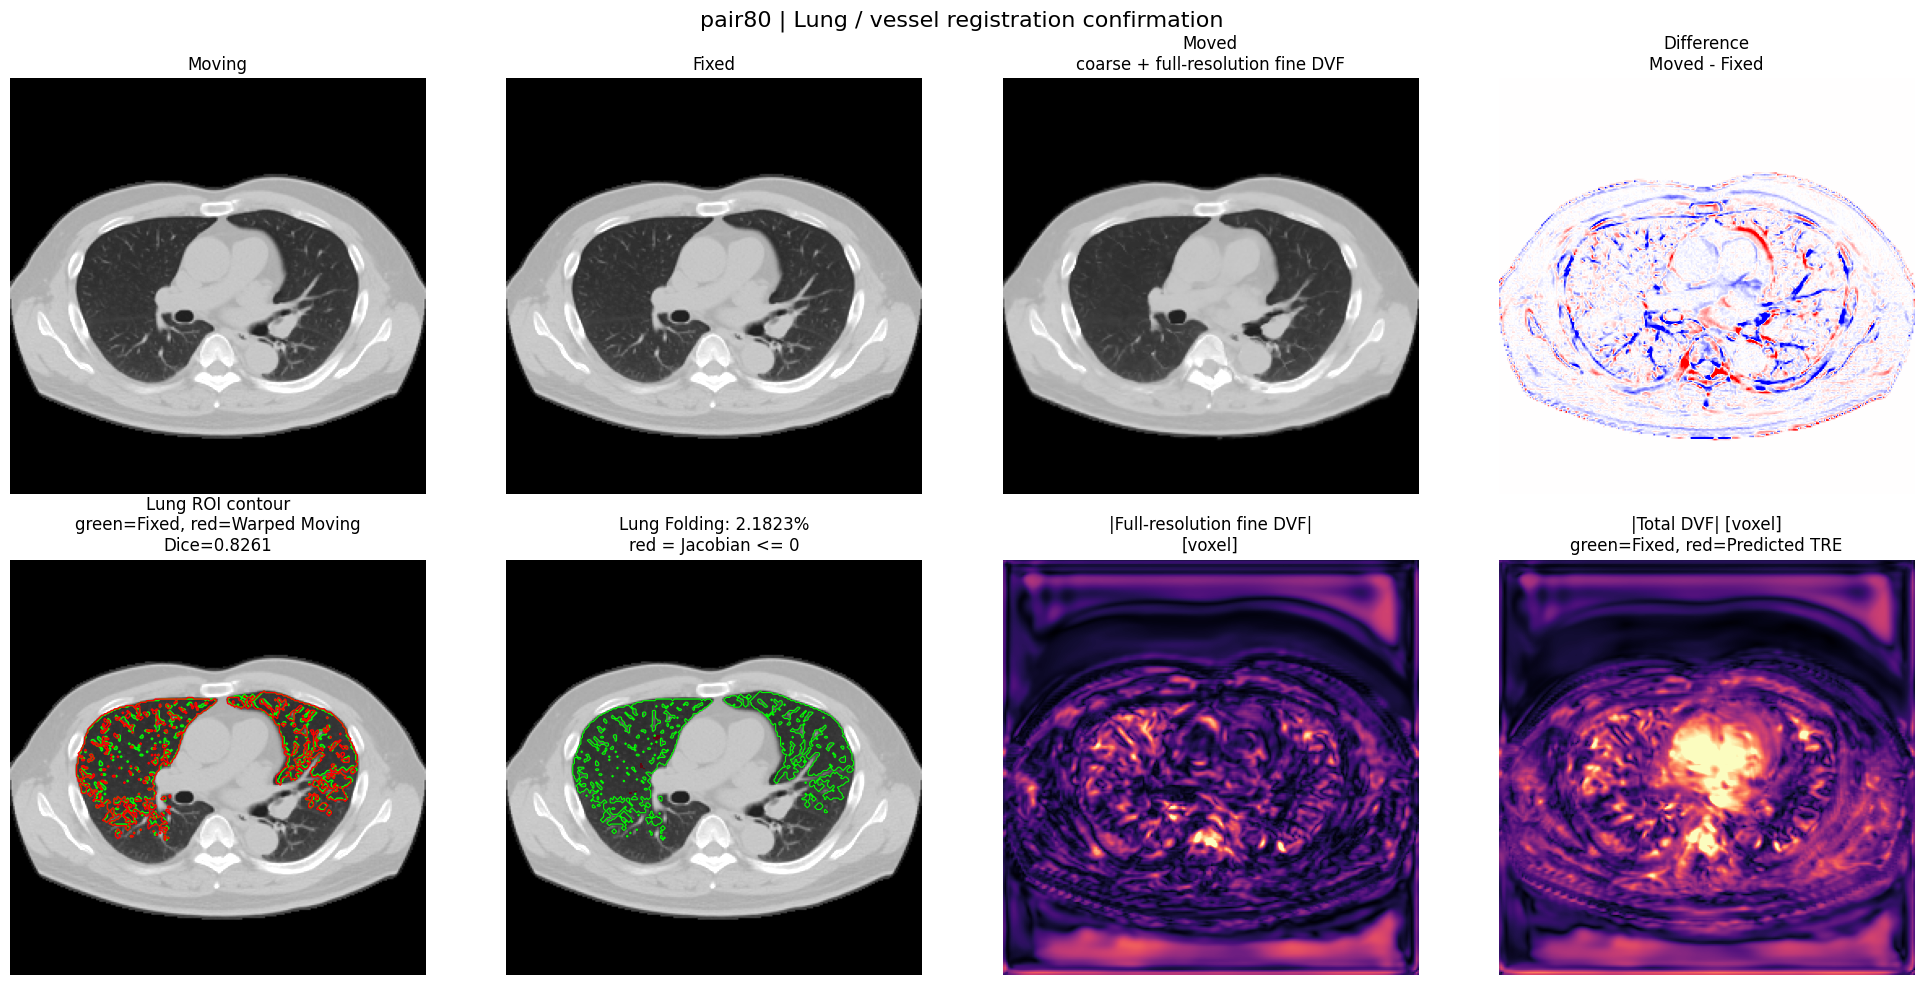


Saved figure:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\manual_lung_vessel_confirmation\pair80_lung_vessel_confirmation.png

Saved metrics CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\manual_lung_vessel_confirmation\pair80_lung_vessel_confirmation.csv


In [20]:
# ============================================================
# Manual confirmation:
# Lung Dice / Lung Folding / fine-DVF / optional vessel TRE
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from scipy.ndimage import (
    binary_fill_holes,
    binary_opening,
    label,
)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

VISUAL_PAIR = "pair80"

# 血管分岐点ランドマークCSVがある場合だけパスを指定する
# 無い場合は None のままでよい
LANDMARK_CSV = None

# 例:
# LANDMARK_CSV = Path(
#     r"D:\Saito\Data\TestData\vessel_landmarks.csv"
# )

# DICOM由来のspacingが分かる場合のみ指定する
# 順番は (z, y, x)
# 例: VOXEL_SPACING_ZYX = (2.5, 0.8, 0.8)
VOXEL_SPACING_ZYX = None

CONFIRM_DIR = (
    RESULT_DIR
    / "manual_lung_vessel_confirmation"
)

CONFIRM_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------
# Required variables check
# ------------------------------------------------------------

required_names = [
    "model",
    "DEVICE",
    "FULL_SIZE",
    "TEST_DATA_ROOT",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    raise NameError(
        "先にfull-resolution fine-DVFモデルの"
        "評価コードを実行してください:\n"
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# Pair / image loading
# ------------------------------------------------------------

def natural_sort_key(path):
    import re

    values = re.findall(
        r"\d+",
        path.name,
    )

    if values:
        return [
            int(value)
            for value in values
        ]

    return [path.name]


def load_volume_confirm(npz_path):
    with np.load(npz_path) as data:
        preferred_keys = [
            "image",
            "volume",
            "ct",
            "data",
            "arr_0",
        ]

        selected_key = next(
            (
                key
                for key in preferred_keys
                if key in data.files
            ),
            data.files[0],
        )

        volume = np.asarray(
            data[selected_key],
            dtype=np.float32,
        )

    volume = np.squeeze(volume)

    if volume.shape == (
        FULL_SIZE[1],
        FULL_SIZE[2],
        FULL_SIZE[0],
    ):
        volume = np.transpose(
            volume,
            (2, 0, 1),
        )

    if tuple(volume.shape) != tuple(FULL_SIZE):
        raise ValueError(
            f"画像サイズが異なります: {npz_path}\n"
            f"shape={volume.shape}"
        )

    return volume


def find_fixed_moving_paths_confirm(pair_dir):
    npz_paths = sorted(
        pair_dir.glob("*.npz"),
        key=natural_sort_key,
    )

    if len(npz_paths) < 2:
        raise FileNotFoundError(
            f"npzが2個以上必要です: {pair_dir}"
        )

    fixed_path = None
    moving_path = None

    for path in npz_paths:
        name = path.stem.lower()

        if "fixed" in name or "target" in name:
            fixed_path = path

        if "moving" in name or "source" in name:
            moving_path = path

    if fixed_path is None:
        fixed_path = npz_paths[0]

    if moving_path is None:
        moving_path = npz_paths[1]

    return fixed_path, moving_path


# ------------------------------------------------------------
# Lung ROI
# ------------------------------------------------------------

def keep_largest_components(mask, n_components=2):
    labeled, count = label(mask)

    if count == 0:
        return np.zeros_like(
            mask,
            dtype=bool,
        )

    counts = np.bincount(
        labeled.ravel()
    )

    counts[0] = 0

    component_ids = np.argsort(
        counts
    )[-n_components:]

    return np.isin(
        labeled,
        component_ids,
    )


def make_lung_mask_confirm(image):
    """
    HU閾値ベースの簡易肺野ROI．
    正確なGT肺野セグメンテーションではない．
    """

    image_01 = np.clip(
        image,
        0.0,
        1.0,
    )

    image_hu = (
        image_01
        * (HU_MAX - HU_MIN)
        + HU_MIN
    )

    body_mask = image_01 > BODY_THRESHOLD

    body_mask = binary_fill_holes(
        body_mask
    )

    lung_candidate = (
        (image_hu >= -1000.0)
        & (image_hu <= -300.0)
        & body_mask
    )

    lung_candidate = binary_opening(
        lung_candidate,
        iterations=1,
    )

    return keep_largest_components(
        lung_candidate,
        n_components=2,
    ).astype(bool)


def dice_score(first_mask, second_mask):
    return float(
        2.0
        * np.logical_and(
            first_mask,
            second_mask,
        ).sum()
        / (
            first_mask.sum()
            + second_mask.sum()
            + 1e-12
        )
    )


# ------------------------------------------------------------
# Mask warp
# ------------------------------------------------------------

def make_sampling_grid_confirm(flow):
    _, _, depth, height, width = flow.shape

    z = torch.arange(
        depth,
        dtype=torch.float32,
        device=flow.device,
    )

    y = torch.arange(
        height,
        dtype=torch.float32,
        device=flow.device,
    )

    x = torch.arange(
        width,
        dtype=torch.float32,
        device=flow.device,
    )

    zz, yy, xx = torch.meshgrid(
        z,
        y,
        x,
        indexing="ij",
    )

    base_grid = torch.stack(
        [
            zz,
            yy,
            xx,
        ],
        dim=0,
    ).unsqueeze(0)

    position = base_grid + flow.float()

    position[:, 0] = (
        2.0
        * position[:, 0]
        / max(depth - 1, 1)
        - 1.0
    )

    position[:, 1] = (
        2.0
        * position[:, 1]
        / max(height - 1, 1)
        - 1.0
    )

    position[:, 2] = (
        2.0
        * position[:, 2]
        / max(width - 1, 1)
        - 1.0
    )

    # grid_sampleの座標順はx, y, z
    return position.permute(
        0,
        2,
        3,
        4,
        1,
    )[..., [2, 1, 0]]


def warp_mask_nearest_confirm(mask_np, flow):
    mask_tensor = torch.from_numpy(
        mask_np.astype(np.float32)
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE
    )

    warped = F.grid_sample(
        mask_tensor,
        make_sampling_grid_confirm(flow),
        mode="nearest",
        padding_mode="zeros",
        align_corners=True,
    )

    return (
        warped[0, 0]
        .detach()
        .cpu()
        .numpy()
        > 0.5
    )


# ------------------------------------------------------------
# Jacobian / Folding
# ------------------------------------------------------------

def jacobian_determinant_confirm(flow_np):
    uz = flow_np[0]
    uy = flow_np[1]
    ux = flow_np[2]

    duz_dz, duz_dy, duz_dx = np.gradient(
        uz,
        edge_order=1,
    )

    duy_dz, duy_dy, duy_dx = np.gradient(
        uy,
        edge_order=1,
    )

    dux_dz, dux_dy, dux_dx = np.gradient(
        ux,
        edge_order=1,
    )

    j11 = 1.0 + duz_dz
    j12 = duz_dy
    j13 = duz_dx

    j21 = duy_dz
    j22 = 1.0 + duy_dy
    j23 = duy_dx

    j31 = dux_dz
    j32 = dux_dy
    j33 = 1.0 + dux_dx

    return (
        j11 * (j22 * j33 - j23 * j32)
        - j12 * (j21 * j33 - j23 * j31)
        + j13 * (j21 * j32 - j22 * j31)
    )


def flow_magnitude_confirm(flow_np):
    return np.sqrt(
        np.sum(
            flow_np ** 2,
            axis=0,
        )
    )


# ------------------------------------------------------------
# Optional vessel TRE
# ------------------------------------------------------------

def normalize_pair_name(value):
    value = str(value).strip().lower()

    if value.isdigit():
        return f"pair{int(value)}"

    return value


def sample_flow_at_points_confirm(
    flow,
    points_zyx,
):
    if len(points_zyx) == 0:
        return np.empty(
            (0, 3),
            dtype=np.float32,
        )

    points = torch.tensor(
        points_zyx,
        dtype=torch.float32,
        device=DEVICE,
    )

    depth = flow.shape[2]
    height = flow.shape[3]
    width = flow.shape[4]

    z = (
        2.0
        * points[:, 0]
        / max(depth - 1, 1)
        - 1.0
    )

    y = (
        2.0
        * points[:, 1]
        / max(height - 1, 1)
        - 1.0
    )

    x = (
        2.0
        * points[:, 2]
        / max(width - 1, 1)
        - 1.0
    )

    # x, y, z順
    grid = torch.stack(
        [
            x,
            y,
            z,
        ],
        dim=1,
    ).view(
        1,
        -1,
        1,
        1,
        3,
    )

    sampled = F.grid_sample(
        flow,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )

    return (
        sampled[0, :, :, 0, 0]
        .transpose(0, 1)
        .detach()
        .cpu()
        .numpy()
    )


# ------------------------------------------------------------
# Load selected pair
# ------------------------------------------------------------

pair_dir = TEST_DATA_ROOT / VISUAL_PAIR

if not pair_dir.is_dir():
    raise FileNotFoundError(
        f"pairフォルダが見つかりません:\n{pair_dir}"
    )

fixed_path, moving_path = (
    find_fixed_moving_paths_confirm(
        pair_dir
    )
)

fixed_np = load_volume_confirm(
    fixed_path
)

moving_np = load_volume_confirm(
    moving_path
)

fixed_tensor = torch.from_numpy(
    fixed_np
).unsqueeze(0).unsqueeze(0).to(
    DEVICE,
    dtype=torch.float32,
)

moving_tensor = torch.from_numpy(
    moving_np
).unsqueeze(0).unsqueeze(0).to(
    DEVICE,
    dtype=torch.float32,
)

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------

model.eval()

with torch.no_grad():
    components = model(
        moving_tensor,
        fixed_tensor,
        return_components=True,
    )

    flow_m2f = components[
        "flow_total_full"
    ]

    moved_tensor = model.transformer_full(
        moving_tensor,
        flow_m2f,
    )

    # TRE計算時だけFixed -> Movingも推論する
    flow_f2m = model(
        fixed_tensor,
        moving_tensor,
    )

moved_np = moved_tensor[
    0,
    0,
].cpu().numpy()

flow_total_np = flow_m2f[
    0
].cpu().numpy()

flow_coarse_np = components[
    "flow_coarse_full"
][0].cpu().numpy()

flow_fine_np = components[
    "flow_fine_full"
][0].cpu().numpy()

# ------------------------------------------------------------
# Lung Dice / Lung Folding
# ------------------------------------------------------------

fixed_lung = make_lung_mask_confirm(
    fixed_np
)

moving_lung = make_lung_mask_confirm(
    moving_np
)

warped_moving_lung = warp_mask_nearest_confirm(
    moving_lung,
    flow_m2f,
)

lung_dice_before = dice_score(
    fixed_lung,
    moving_lung,
)

lung_dice_after = dice_score(
    fixed_lung,
    warped_moving_lung,
)

jacobian = jacobian_determinant_confirm(
    flow_total_np
)

lung_folding_mask = (
    (jacobian <= 0.0)
    & fixed_lung
)

lung_folding_percent = float(
    lung_folding_mask.sum()
    / (fixed_lung.sum() + 1e-12)
    * 100.0
)

# 肺野面積が最大となるsliceを自動選択
slice_index = int(
    np.argmax(
        fixed_lung.sum(
            axis=(1, 2)
        )
    )
)

# ------------------------------------------------------------
# Optional vessel TRE
# ------------------------------------------------------------

vessel_tre_voxel_mean = np.nan
vessel_tre_mm_mean = np.nan
n_landmarks = 0

fixed_points = np.empty(
    (0, 3),
    dtype=np.float32,
)

predicted_fixed_points = np.empty(
    (0, 3),
    dtype=np.float32,
)

if LANDMARK_CSV is not None:
    LANDMARK_CSV = Path(
        LANDMARK_CSV
    )

    landmark_df = pd.read_csv(
        LANDMARK_CSV
    )

    required_columns = [
        "pair",
        "moving_z",
        "moving_y",
        "moving_x",
        "fixed_z",
        "fixed_y",
        "fixed_x",
    ]

    missing_columns = [
        name
        for name in required_columns
        if name not in landmark_df.columns
    ]

    if missing_columns:
        raise ValueError(
            "ランドマークCSVに必要な列がありません:\n"
            + ", ".join(missing_columns)
        )

    landmark_df["pair_normalized"] = (
        landmark_df["pair"].map(
            normalize_pair_name
        )
    )

    selected_landmarks = landmark_df[
        landmark_df["pair_normalized"]
        == normalize_pair_name(
            VISUAL_PAIR
        )
    ]

    if len(selected_landmarks) > 0:
        moving_points = selected_landmarks[
            [
                "moving_z",
                "moving_y",
                "moving_x",
            ]
        ].to_numpy(
            dtype=np.float32
        )

        fixed_points = selected_landmarks[
            [
                "fixed_z",
                "fixed_y",
                "fixed_x",
            ]
        ].to_numpy(
            dtype=np.float32
        )

        # Fixed -> Moving DVFをMoving座標で参照することで，
        # Moving landmarkのFixed予測座標を求める
        reverse_flow = sample_flow_at_points_confirm(
            flow_f2m,
            moving_points,
        )

        predicted_fixed_points = (
            moving_points
            + reverse_flow
        )

        error_zyx = (
            predicted_fixed_points
            - fixed_points
        )

        error_voxel = np.sqrt(
            np.sum(
                error_zyx ** 2,
                axis=1,
            )
        )

        vessel_tre_voxel_mean = float(
            error_voxel.mean()
        )

        if VOXEL_SPACING_ZYX is not None:
            error_mm = np.sqrt(
                np.sum(
                    (
                        error_zyx
                        * np.asarray(
                            VOXEL_SPACING_ZYX,
                            dtype=np.float32,
                        )
                    ) ** 2,
                    axis=1,
                )
            )

            vessel_tre_mm_mean = float(
                error_mm.mean()
            )

        n_landmarks = len(
            selected_landmarks
        )

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 70)
print("MANUAL LUNG / VESSEL CONFIRMATION")
print("=" * 70)
print("Pair                  :", VISUAL_PAIR)
print("Selected axial slice  :", slice_index)
print("Fixed lung voxels     :", int(fixed_lung.sum()))
print("Moving lung voxels    :", int(moving_lung.sum()))
print()
print(
    f"Lung Dice before      : {lung_dice_before:.6f}"
)
print(
    f"Lung Dice after       : {lung_dice_after:.6f}"
)
print(
    f"Lung Folding          : {lung_folding_percent:.6f}%"
)
print(
    "Lung Jacobian minimum :",
    f"{jacobian[fixed_lung].min():.6f}",
)
print()
print(
    f"Vessel landmarks     : {n_landmarks}"
)
print(
    f"Vessel TRE [voxel]   : {vessel_tre_voxel_mean:.6f}"
)

if VOXEL_SPACING_ZYX is not None:
    print(
        f"Vessel TRE [mm]      : {vessel_tre_mm_mean:.6f}"
    )
else:
    print(
        "Vessel TRE [mm]      : NaN "
        "(VOXEL_SPACING_ZYX未設定)"
    )

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

vmin, vmax = np.percentile(
    np.concatenate(
        [
            moving_np.ravel(),
            fixed_np.ravel(),
            moved_np.ravel(),
        ]
    ),
    [1, 99],
)

difference = (
    moved_np[slice_index]
    - fixed_np[slice_index]
)

difference_limit = np.percentile(
    np.abs(difference),
    99,
)

coarse_magnitude = flow_magnitude_confirm(
    flow_coarse_np
)

fine_magnitude = flow_magnitude_confirm(
    flow_fine_np
)

total_magnitude = flow_magnitude_confirm(
    flow_total_np
)

magnitude_limit = np.percentile(
    np.concatenate(
        [
            coarse_magnitude.ravel(),
            fine_magnitude.ravel(),
            total_magnitude.ravel(),
        ]
    ),
    99,
)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(20, 10),
)

# Moving
axes[0, 0].imshow(
    moving_np[slice_index],
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)
axes[0, 0].set_title(
    "Moving"
)
axes[0, 0].axis("off")

# Fixed
axes[0, 1].imshow(
    fixed_np[slice_index],
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)
axes[0, 1].set_title(
    "Fixed"
)
axes[0, 1].axis("off")

# Moved
axes[0, 2].imshow(
    moved_np[slice_index],
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)
axes[0, 2].set_title(
    "Moved\ncoarse + full-resolution fine DVF"
)
axes[0, 2].axis("off")

# Difference
axes[0, 3].imshow(
    difference,
    cmap="bwr",
    vmin=-difference_limit,
    vmax=difference_limit,
)
axes[0, 3].set_title(
    "Difference\nMoved - Fixed"
)
axes[0, 3].axis("off")

# Lung Dice contours
axes[1, 0].imshow(
    fixed_np[slice_index],
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)

axes[1, 0].contour(
    fixed_lung[slice_index],
    levels=[0.5],
    colors="lime",
    linewidths=1.0,
)

axes[1, 0].contour(
    warped_moving_lung[slice_index],
    levels=[0.5],
    colors="red",
    linewidths=1.0,
)

axes[1, 0].set_title(
    f"Lung ROI contour\n"
    f"green=Fixed, red=Warped Moving\n"
    f"Dice={lung_dice_after:.4f}"
)

axes[1, 0].axis("off")

# Lung Folding
axes[1, 1].imshow(
    fixed_np[slice_index],
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)

axes[1, 1].imshow(
    np.ma.masked_where(
        ~lung_folding_mask[slice_index],
        lung_folding_mask[slice_index],
    ),
    cmap="Reds",
    alpha=0.90,
    vmin=0.0,
    vmax=1.0,
)

axes[1, 1].contour(
    fixed_lung[slice_index],
    levels=[0.5],
    colors="lime",
    linewidths=0.8,
)

axes[1, 1].set_title(
    f"Lung Folding: {lung_folding_percent:.4f}%\n"
    "red = Jacobian <= 0"
)

axes[1, 1].axis("off")

# Fine DVF magnitude
axes[1, 2].imshow(
    fine_magnitude[slice_index],
    cmap="magma",
    vmin=0.0,
    vmax=magnitude_limit,
)

axes[1, 2].set_title(
    "|Full-resolution fine DVF|\n"
    "[voxel]"
)

axes[1, 2].axis("off")

# Total DVF magnitude + landmark
axes[1, 3].imshow(
    total_magnitude[slice_index],
    cmap="magma",
    vmin=0.0,
    vmax=magnitude_limit,
)

for fixed_point, predicted_point in zip(
    fixed_points,
    predicted_fixed_points,
):
    if abs(
        fixed_point[0]
        - slice_index
    ) <= 1.0:
        axes[1, 3].plot(
            fixed_point[2],
            fixed_point[1],
            "go",
            markersize=5,
            label="Fixed landmark",
        )

        axes[1, 3].plot(
            predicted_point[2],
            predicted_point[1],
            "rx",
            markersize=6,
            label="Predicted landmark",
        )

axes[1, 3].set_title(
    "|Total DVF| [voxel]\n"
    "green=Fixed, red=Predicted TRE"
)

axes[1, 3].axis("off")

fig.suptitle(
    f"{VISUAL_PAIR} | Lung / vessel registration confirmation",
    fontsize=16,
)

plt.tight_layout()

figure_path = (
    CONFIRM_DIR
    / f"{VISUAL_PAIR}_lung_vessel_confirmation.png"
)

fig.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Save single-pair result
# ------------------------------------------------------------

single_pair_result = pd.DataFrame(
    [
        {
            "pair": VISUAL_PAIR,
            "slice_index": slice_index,
            "lung_dice_before": lung_dice_before,
            "lung_dice_after": lung_dice_after,
            "lung_folding_percent": lung_folding_percent,
            "lung_jacobian_min": float(
                jacobian[fixed_lung].min()
            ),
            "vessel_tre_voxel_mean": vessel_tre_voxel_mean,
            "vessel_tre_mm_mean": vessel_tre_mm_mean,
            "n_vessel_landmarks": n_landmarks,
        }
    ]
)

single_pair_csv_path = (
    CONFIRM_DIR
    / f"{VISUAL_PAIR}_lung_vessel_confirmation.csv"
)

single_pair_result.to_csv(
    single_pair_csv_path,
    index=False,
    encoding="utf-8-sig",
)

print("\nSaved figure:")
print(figure_path)

print("\nSaved metrics CSV:")
print(single_pair_csv_path)

del fixed_tensor
del moving_tensor
del moved_tensor
del flow_m2f
del flow_f2m
del components

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [12]:
# ============================================================
# 9. Load checkpoint
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
)

checkpoint_config = checkpoint.get(
    "config",
    {},
)

fine_base_channels = int(
    checkpoint_config.get(
        "fine_base_channels",
        4,
    )
)

fine_flow_scale = float(
    checkpoint_config.get(
        "fine_flow_scale",
        0.5,
    )
)

print("fine_base_channels:", fine_base_channels)
print("fine_flow_scale   :", fine_flow_scale)

model = CoarseToFineFullResDVF(
    fine_flow_scale=fine_flow_scale,
    fine_base_channels=fine_base_channels,
).to(DEVICE)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint,
)

model.load_state_dict(
    state_dict,
    strict=True,
)

model.eval()

print("Model loaded successfully.")

fine_base_channels: 4
fine_flow_scale   : 0.5
[64, 128, 128]
Model loaded successfully.


In [13]:
# ============================================================
# 10. Evaluate one pair
# ============================================================

@torch.no_grad()
def evaluate_pair(pair_dir):
    fixed_path, moving_path = find_fixed_moving_paths(
        pair_dir
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    # Moving -> Fixed
    flow_m2f_full = model(
        moving_tensor,
        fixed_tensor,
    )

    moved_tensor = transformer_full(
        moving_tensor,
        flow_m2f_full,
    )

    # Fixed -> Moving
    flow_f2m_full = model(
        fixed_tensor,
        moving_tensor,
    )

    ic_mse = inverse_consistency_mse(
        flow_m2f_full,
        flow_f2m_full,
        transformer_low,
    )

    moved_np = moved_tensor[
        0,
        0,
    ].detach().cpu().numpy()

    flow_np = flow_m2f_full[
        0
    ].detach().cpu().numpy()

    mse_before = float(
        np.mean(
            (moving_np - fixed_np) ** 2
        )
    )

    mse_after = float(
        np.mean(
            (moved_np - fixed_np) ** 2
        )
    )

    rmse_before = float(
        np.sqrt(mse_before)
    )

    rmse_after = float(
        np.sqrt(mse_after)
    )

    rmse_hu_before = (
        rmse_before
        * (HU_MAX - HU_MIN)
    )

    rmse_hu_after = (
        rmse_after
        * (HU_MAX - HU_MIN)
    )

    ncc_before = compute_ncc(
        fixed_np,
        moving_np,
    )

    ncc_after = compute_ncc(
        fixed_np,
        moved_np,
    )

    fixed_mask = compute_body_mask(
        fixed_np
    )

    moving_mask = compute_body_mask(
        moving_np
    )

    moved_mask = compute_body_mask(
        moved_np
    )

    dice_before, jaccard_before = (
        compute_dice_jaccard(
            fixed_mask,
            moving_mask,
        )
    )

    dice_after, jaccard_after = (
        compute_dice_jaccard(
            fixed_mask,
            moved_mask,
        )
    )

    ssim_before = compute_slice_ssim(
        fixed_np,
        moving_np,
    )

    ssim_after = compute_slice_ssim(
        fixed_np,
        moved_np,
    )

    ms_ssim, fsim = compute_piq_metrics(
        fixed_np,
        moved_np,
    )

    jacobian = jacobian_determinant_numpy(
        flow_np
    )

    folding_percent = float(
        np.mean(jacobian <= 0.0) * 100.0
    )

    flow_mag = flow_magnitude(
        flow_np
    )

    result = {
        "pair": pair_dir.name,
        "fixed_file": fixed_path.name,
        "moving_file": moving_path.name,

        "mse_before": mse_before,
        "mse_after": mse_after,

        "rmse_normalized_before": rmse_before,
        "rmse_normalized_after": rmse_after,

        "rmse_hu_before": rmse_hu_before,
        "rmse_hu_after": rmse_hu_after,

        "ncc_before": ncc_before,
        "ncc_after": ncc_after,

        "dice_before": dice_before,
        "dice_after": dice_after,

        "jaccard_before": jaccard_before,
        "jaccard_after": jaccard_after,

        "ssim_before": ssim_before,
        "ssim_after": ssim_after,

        "ms_ssim_after": ms_ssim,
        "fsim_after": fsim,

        "folding_percent": folding_percent,
        "jacobian_min": float(jacobian.min()),
        "jacobian_mean": float(jacobian.mean()),

        "flow_magnitude_mean_voxel": float(
            flow_mag.mean()
        ),

        "flow_magnitude_max_voxel": float(
            flow_mag.max()
        ),

        "ic_mse_low": float(ic_mse),
    }

    del fixed_tensor
    del moving_tensor
    del flow_m2f_full
    del flow_f2m_full
    del moved_tensor

    return result



In [14]:
# ============================================================
# 11. Evaluate all TestData pairs
# ============================================================

pair_dirs = sorted(
    [
        path
        for path in TEST_DATA_ROOT.iterdir()
        if path.is_dir()
    ],
    key=natural_sort_key,
)

if len(pair_dirs) == 0:
    raise FileNotFoundError(
        f"pairフォルダがありません: {TEST_DATA_ROOT}"
    )

print("\n" + "=" * 70)
print("FULL-RESOLUTION FINE-DVF TEST EVALUATION")
print("=" * 70)
print("Number of pairs:", len(pair_dirs))

results = []

for index, pair_dir in enumerate(
    tqdm(
        pair_dirs,
        desc="TestData evaluation",
    ),
    start=1,
):
    try:
        result = evaluate_pair(
            pair_dir
        )

        results.append(result)

        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{result['pair']} | "
            f"Dice={result['dice_after']:.5f} | "
            f"NCC={result['ncc_after']:.5f} | "
            f"Folding={result['folding_percent']:.4f}% | "
            f"IC={result['ic_mse_low']:.6f}"
        )

    except Exception as error:
        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{pair_dir.name} skipped: {error}"
        )

    if torch.cuda.is_available() and index % 10 == 0:
        torch.cuda.empty_cache()

    gc.collect()

if len(results) == 0:
    raise RuntimeError(
        "評価に成功したpairがありません．"
    )

pairwise_df = pd.DataFrame(
    results
).sort_values(
    "pair",
    key=lambda column: column.map(
        lambda value: natural_sort_key(
            Path(value)
        )
    ),
).reset_index(
    drop=True
)

pairwise_csv_path = (
    RESULT_DIR
    / "fullres_fine_dvf_test_metrics.csv"
)

pairwise_df.to_csv(
    pairwise_csv_path,
    index=False,
    encoding="utf-8-sig",
)



FULL-RESOLUTION FINE-DVF TEST EVALUATION
Number of pairs: 101


TestData evaluation:   0%|          | 0/101 [00:00<?, ?it/s]

[001/101] pair1 | Dice=0.98980 | NCC=0.98380 | Folding=2.0241% | IC=0.218599
[002/101] pair2 | Dice=0.99503 | NCC=0.99487 | Folding=1.7976% | IC=0.173937
[003/101] pair3 | Dice=0.99152 | NCC=0.98840 | Folding=1.7535% | IC=0.173470
[004/101] pair4 | Dice=0.99422 | NCC=0.99377 | Folding=1.6519% | IC=0.137492
[005/101] pair5 | Dice=0.99654 | NCC=0.99508 | Folding=1.6621% | IC=0.142420
[006/101] pair6 | Dice=0.99685 | NCC=0.99550 | Folding=1.6292% | IC=0.165417
[007/101] pair7 | Dice=0.99558 | NCC=0.99230 | Folding=2.0611% | IC=0.193268
[008/101] pair8 | Dice=0.99516 | NCC=0.99203 | Folding=2.1188% | IC=0.215683
[009/101] pair9 | Dice=0.99580 | NCC=0.99545 | Folding=1.7062% | IC=0.134166
[010/101] pair10 | Dice=0.99525 | NCC=0.99436 | Folding=1.8766% | IC=0.139799
[011/101] pair11 | Dice=0.99114 | NCC=0.98419 | Folding=2.0151% | IC=0.190117
[012/101] pair12 | Dice=0.99329 | NCC=0.99237 | Folding=3.2891% | IC=0.618345
[013/101] pair13 | Dice=0.99580 | NCC=0.99669 | Folding=1.3621% | IC=0.11

In [15]:
# ============================================================
# 12. Summary table
# ============================================================

worst_folding_row = pairwise_df.loc[
    pairwise_df["folding_percent"].idxmax()
]

summary_df = pd.DataFrame(
    [
        {
            "model": MODEL_PATH.stem,

            "n_pairs": len(pairwise_df),

            "dice_before_mean": pairwise_df[
                "dice_before"
            ].mean(),

            "dice_after_mean": pairwise_df[
                "dice_after"
            ].mean(),

            "dice_improvement": (
                pairwise_df["dice_after"].mean()
                - pairwise_df["dice_before"].mean()
            ),

            "jaccard_after_mean": pairwise_df[
                "jaccard_after"
            ].mean(),

            "ncc_before_mean": pairwise_df[
                "ncc_before"
            ].mean(),

            "ncc_after_mean": pairwise_df[
                "ncc_after"
            ].mean(),

            "ncc_improvement": (
                pairwise_df["ncc_after"].mean()
                - pairwise_df["ncc_before"].mean()
            ),

            "rmse_hu_before_mean": pairwise_df[
                "rmse_hu_before"
            ].mean(),

            "rmse_hu_after_mean": pairwise_df[
                "rmse_hu_after"
            ].mean(),

            "rmse_hu_improvement": (
                pairwise_df["rmse_hu_before"].mean()
                - pairwise_df["rmse_hu_after"].mean()
            ),

            "ssim_after_mean": pairwise_df[
                "ssim_after"
            ].mean(),

            "ms_ssim_after_mean": pairwise_df[
                "ms_ssim_after"
            ].mean(),

            "fsim_after_mean": pairwise_df[
                "fsim_after"
            ].mean(),

            "folding_mean_percent": pairwise_df[
                "folding_percent"
            ].mean(),

            "folding_max_percent": pairwise_df[
                "folding_percent"
            ].max(),

            "worst_folding_pair": worst_folding_row[
                "pair"
            ],

            "ic_mse_low_mean": pairwise_df[
                "ic_mse_low"
            ].mean(),

            "flow_magnitude_mean_voxel": pairwise_df[
                "flow_magnitude_mean_voxel"
            ].mean(),
        }
    ]
)

summary_csv_path = (
    RESULT_DIR
    / "fullres_fine_dvf_test_summary.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 70)
print("FULL-RESOLUTION FINE-DVF TEST SUMMARY")
print("=" * 70)

display(
    summary_df.round(6)
)

print("\nPair-wise CSV:")
print(pairwise_csv_path)

print("\nSummary CSV:")
print(summary_csv_path)



FULL-RESOLUTION FINE-DVF TEST SUMMARY


,model,n_pairs,dice_before_mean,dice_after_mean,dice_improvement,jaccard_after_mean,ncc_before_mean,ncc_after_mean,ncc_improvement,rmse_hu_before_mean,rmse_hu_after_mean,rmse_hu_improvement,ssim_after_mean,ms_ssim_after_mean,fsim_after_mean,folding_mean_percent,folding_max_percent,worst_folding_pair,ic_mse_low_mean,flow_magnitude_mean_voxel
0,model_coarse_to_fine_fullres_fine_dvf_30k_final,101,0.959418,0.990846,0.031428,0.982161,0.920009,0.987656,0.067647,411.771444,150.240902,261.530542,0.921751,NaN,NaN,2.516235,6.301153,pair90,0.622271,1.829294



Pair-wise CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\fullres_fine_dvf_test_metrics.csv

Summary CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\fullres_fine_dvf_test_summary.csv


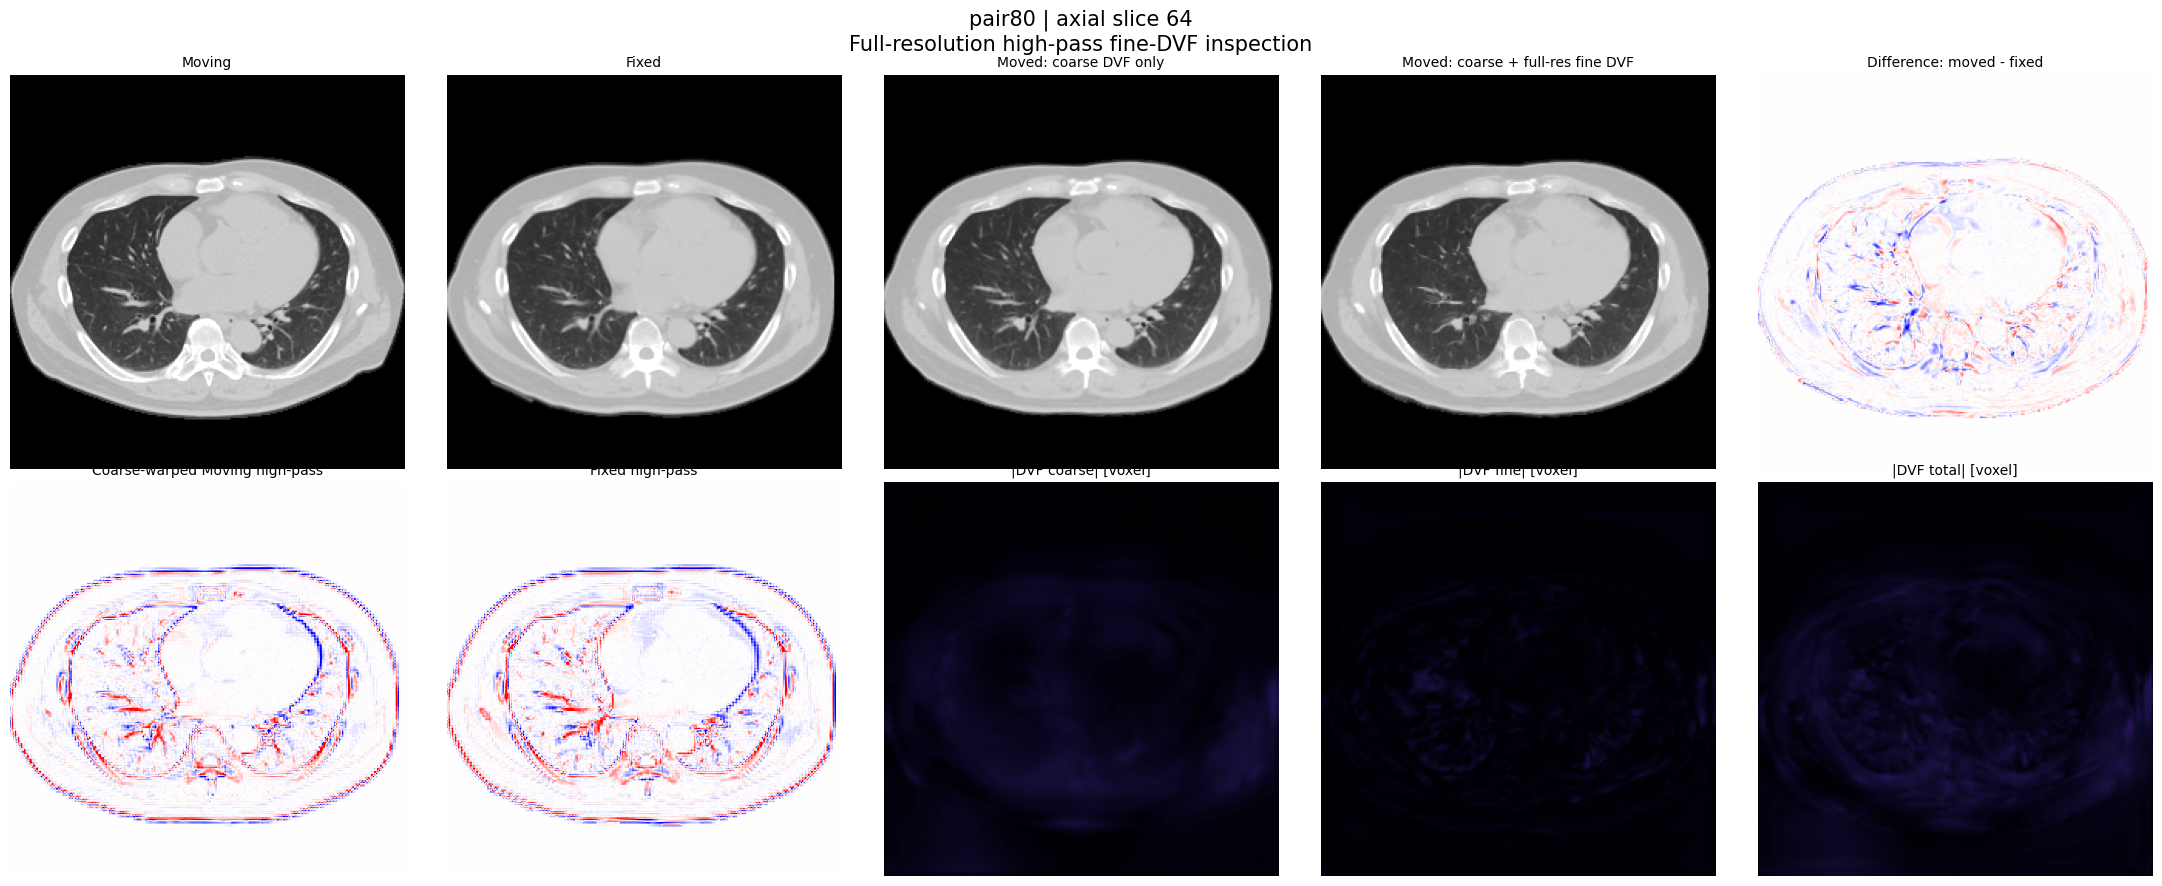


Component visualization:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\pair80_fullres_fine_dvf_components.png

Saved DVF components:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\pair80_fullres_dvf_components.npz


In [16]:
# ============================================================
# 13. Visualize and save DVF components for one pair
# ============================================================

visual_pair_dir = next(
    (
        path
        for path in pair_dirs
        if path.name == VISUAL_PAIR
    ),
    None,
)

if visual_pair_dir is None:
    print(
        f"\n{VISUAL_PAIR} が見つからないため，可視化を省略します．"
    )

else:
    fixed_path, moving_path = find_fixed_moving_paths(
        visual_pair_dir
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    with torch.no_grad():
        components = model(
            moving_tensor,
            fixed_tensor,
            return_components=True,
        )

        moved_coarse_tensor = transformer_full(
            moving_tensor,
            components["flow_coarse_full"],
        )

        moved_total_tensor = transformer_full(
            moving_tensor,
            components["flow_total_full"],
        )

    moved_coarse_np = moved_coarse_tensor[
        0,
        0,
    ].cpu().numpy()

    moved_total_np = moved_total_tensor[
        0,
        0,
    ].cpu().numpy()

    moving_high_np = components[
        "moving_high_full"
    ][0, 0].cpu().numpy()

    fixed_high_np = components[
        "fixed_high_full"
    ][0, 0].cpu().numpy()

    flow_coarse_np = components[
        "flow_coarse_full"
    ][0].cpu().numpy()

    flow_fine_np = components[
        "flow_fine_full"
    ][0].cpu().numpy()

    flow_total_np = components[
        "flow_total_full"
    ][0].cpu().numpy()

    slice_index = FULL_SIZE[0] // 2

    vmin, vmax = np.percentile(
        np.concatenate(
            [
                moving_np.ravel(),
                fixed_np.ravel(),
                moved_coarse_np.ravel(),
                moved_total_np.ravel(),
            ]
        ),
        [1, 99],
    )

    high_abs_max = np.percentile(
        np.abs(
            np.concatenate(
                [
                    moving_high_np.ravel(),
                    fixed_high_np.ravel(),
                ]
            )
        ),
        99,
    )

    coarse_magnitude = flow_magnitude(
        flow_coarse_np
    )

    fine_magnitude = flow_magnitude(
        flow_fine_np
    )

    total_magnitude = flow_magnitude(
        flow_total_np
    )

    mag_max = np.percentile(
        np.concatenate(
            [
                coarse_magnitude.ravel(),
                fine_magnitude.ravel(),
                total_magnitude.ravel(),
            ]
        ),
        99,
    )

    fig, axes = plt.subplots(
        2,
        5,
        figsize=(22, 9),
    )

    image_items = [
        (
            moving_np[slice_index],
            "Moving",
            "gray",
            vmin,
            vmax,
        ),
        (
            fixed_np[slice_index],
            "Fixed",
            "gray",
            vmin,
            vmax,
        ),
        (
            moved_coarse_np[slice_index],
            "Moved: coarse DVF only",
            "gray",
            vmin,
            vmax,
        ),
        (
            moved_total_np[slice_index],
            "Moved: coarse + full-res fine DVF",
            "gray",
            vmin,
            vmax,
        ),
        (
            moved_total_np[slice_index]
            - fixed_np[slice_index],
            "Difference: moved - fixed",
            "bwr",
            -0.25,
            0.25,
        ),
        (
            moving_high_np[slice_index],
            "Coarse-warped Moving high-pass",
            "bwr",
            -high_abs_max,
            high_abs_max,
        ),
        (
            fixed_high_np[slice_index],
            "Fixed high-pass",
            "bwr",
            -high_abs_max,
            high_abs_max,
        ),
        (
            coarse_magnitude[slice_index],
            "|DVF coarse| [voxel]",
            "magma",
            0.0,
            mag_max,
        ),
        (
            fine_magnitude[slice_index],
            "|DVF fine| [voxel]",
            "magma",
            0.0,
            mag_max,
        ),
        (
            total_magnitude[slice_index],
            "|DVF total| [voxel]",
            "magma",
            0.0,
            mag_max,
        ),
    ]

    for axis, item in zip(
        axes.ravel(),
        image_items,
    ):
        image, title, cmap, item_vmin, item_vmax = item

        axis.imshow(
            image,
            cmap=cmap,
            vmin=item_vmin,
            vmax=item_vmax,
        )

        axis.set_title(
            title,
            fontsize=10,
        )

        axis.axis("off")

    fig.suptitle(
        f"{VISUAL_PAIR} | axial slice {slice_index}\n"
        "Full-resolution high-pass fine-DVF inspection",
        fontsize=15,
    )

    plt.tight_layout()

    visual_png_path = (
        RESULT_DIR
        / f"{VISUAL_PAIR}_fullres_fine_dvf_components.png"
    )

    fig.savefig(
        visual_png_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    component_npz_path = (
        RESULT_DIR
        / f"{VISUAL_PAIR}_fullres_dvf_components.npz"
    )

    np.savez_compressed(
        component_npz_path,
        flow_coarse_full=flow_coarse_np.astype(
            np.float32
        ),
        flow_fine_full=flow_fine_np.astype(
            np.float32
        ),
        flow_total_full=flow_total_np.astype(
            np.float32
        ),
        moving_high_full=moving_high_np.astype(
            np.float32
        ),
        fixed_high_full=fixed_high_np.astype(
            np.float32
        ),
    )

    print("\nComponent visualization:")
    print(visual_png_path)

    print("\nSaved DVF components:")
    print(component_npz_path)

    del components
    del fixed_tensor
    del moving_tensor
    del moved_coarse_tensor
    del moved_total_tensor

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [ ]:
# ============================================================
# All TestData:
# Coarse-only vs Coarse + full-resolution fine-DVF comparison
# ============================================================

required_names = [
    "model",
    "pair_dirs",
    "DEVICE",
    "find_fixed_moving_paths_confirm",
    "load_volume_confirm",
    "make_lung_mask_confirm",
    "warp_mask_nearest_confirm",
    "jacobian_determinant_confirm",
    "dice_score",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    raise NameError(
        "先にfull-resolution fine-DVF評価セルと"
        "MANUAL LUNG / VESSEL CONFIRMATIONセルを実行してください:\n"
        + ", ".join(missing)
    )

COMPARE_DIR = (
    RESULT_DIR
    / "coarse_only_vs_full_fine_comparison"
)

COMPARE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LANDMARK_CSV = None
VOXEL_SPACING_ZYX = None


def ncc_compare(first, second):
    first = first.astype(np.float64)
    second = second.astype(np.float64)

    first = first - first.mean()
    second = second - second.mean()

    return float(
        np.sum(first * second)
        / (
            np.sqrt(
                np.sum(first ** 2)
                * np.sum(second ** 2)
            )
            + 1e-12
        )
    )


def body_dice_compare(fixed, moved):
    fixed_mask = binary_fill_holes(
        np.clip(fixed, 0.0, 1.0)
        > BODY_THRESHOLD
    )

    moved_mask = binary_fill_holes(
        np.clip(moved, 0.0, 1.0)
        > BODY_THRESHOLD
    )

    return dice_score(
        fixed_mask,
        moved_mask,
    )


@torch.no_grad()
def evaluate_coarse_vs_full(pair_dir):
    fixed_path, moving_path = (
        find_fixed_moving_paths(
            pair_dir
        )
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    components = model(
        moving_tensor,
        fixed_tensor,
        return_components=True,
    )

    flow_coarse = components[
        "flow_coarse_full"
    ]

    flow_full = components[
        "flow_total_full"
    ]

    moved_coarse = model.transformer_full(
        moving_tensor,
        flow_coarse,
    )

    moved_full = model.transformer_full(
        moving_tensor,
        flow_full,
    )

    moved_coarse_np = moved_coarse[
        0, 0
    ].cpu().numpy()

    moved_full_np = moved_full[
        0, 0
    ].cpu().numpy()

    flow_coarse_np = flow_coarse[
        0
    ].cpu().numpy()

    flow_full_np = flow_full[
        0
    ].cpu().numpy()

    # --------------------------------------------------------
    # Global image metrics
    # --------------------------------------------------------

    coarse_dice = body_dice_compare(
        fixed_np,
        moved_coarse_np,
    )

    full_dice = body_dice_compare(
        fixed_np,
        moved_full_np,
    )

    coarse_ncc = ncc_compare(
        fixed_np,
        moved_coarse_np,
    )

    full_ncc = ncc_compare(
        fixed_np,
        moved_full_np,
    )

    coarse_rmse_hu = float(
        np.sqrt(
            np.mean(
                (fixed_np - moved_coarse_np) ** 2
            )
        )
        * (HU_MAX - HU_MIN)
    )

    full_rmse_hu = float(
        np.sqrt(
            np.mean(
                (fixed_np - moved_full_np) ** 2
            )
        )
        * (HU_MAX - HU_MIN)
    )

    # --------------------------------------------------------
    # Lung Dice
    # --------------------------------------------------------

    fixed_lung = make_lung_mask_confirm(
        fixed_np
    )

    moving_lung = make_lung_mask_confirm(
        moving_np
    )

    warped_lung_coarse = warp_mask_nearest_confirm(
        moving_lung,
        flow_coarse,
    )

    warped_lung_full = warp_mask_nearest_confirm(
        moving_lung,
        flow_full,
    )

    lung_dice_coarse = dice_score(
        fixed_lung,
        warped_lung_coarse,
    )

    lung_dice_full = dice_score(
        fixed_lung,
        warped_lung_full,
    )

    # --------------------------------------------------------
    # Global / lung Folding
    # --------------------------------------------------------

    jac_coarse = jacobian_determinant_confirm(
        flow_coarse_np
    )

    jac_full = jacobian_determinant_confirm(
        flow_full_np
    )

    folding_coarse = float(
        np.mean(jac_coarse <= 0.0)
        * 100.0
    )

    folding_full = float(
        np.mean(jac_full <= 0.0)
        * 100.0
    )

    lung_folding_coarse = float(
        np.mean(
            jac_coarse[fixed_lung] <= 0.0
        )
        * 100.0
    )

    lung_folding_full = float(
        np.mean(
            jac_full[fixed_lung] <= 0.0
        )
        * 100.0
    )

    result = {
        "pair": pair_dir.name,

        "coarse_dice": coarse_dice,
        "full_dice": full_dice,
        "full_minus_coarse_dice": (
            full_dice - coarse_dice
        ),

        "coarse_ncc": coarse_ncc,
        "full_ncc": full_ncc,
        "full_minus_coarse_ncc": (
            full_ncc - coarse_ncc
        ),

        "coarse_rmse_hu": coarse_rmse_hu,
        "full_rmse_hu": full_rmse_hu,
        "full_minus_coarse_rmse_hu": (
            full_rmse_hu - coarse_rmse_hu
        ),

        "coarse_lung_dice": lung_dice_coarse,
        "full_lung_dice": lung_dice_full,
        "full_minus_coarse_lung_dice": (
            lung_dice_full - lung_dice_coarse
        ),

        "coarse_folding_percent": folding_coarse,
        "full_folding_percent": folding_full,
        "full_minus_coarse_folding_percent": (
            folding_full - folding_coarse
        ),

        "coarse_lung_folding_percent": (
            lung_folding_coarse
        ),

        "full_lung_folding_percent": (
            lung_folding_full
        ),

        "full_minus_coarse_lung_folding_percent": (
            lung_folding_full
            - lung_folding_coarse
        ),

        "coarse_jacobian_min": float(
            jac_coarse.min()
        ),

        "full_jacobian_min": float(
            jac_full.min()
        ),
    }

    del fixed_tensor
    del moving_tensor
    del components
    del flow_coarse
    del flow_full
    del moved_coarse
    del moved_full

    return result


# ============================================================
# Run all pairs
# ============================================================

comparison_results = []

print("=" * 70)
print("COARSE-ONLY vs COARSE + FULL-RESOLUTION FINE-DVF")
print("=" * 70)

for index, pair_dir in enumerate(
    tqdm(
        pair_dirs,
        desc="Coarse vs full fine",
    ),
    start=1,
):
    try:
        result = evaluate_coarse_vs_full(
            pair_dir
        )

        comparison_results.append(
            result
        )

        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{result['pair']} | "
            f"Dice: {result['coarse_dice']:.5f}"
            f" -> {result['full_dice']:.5f} | "
            f"LungFold: "
            f"{result['coarse_lung_folding_percent']:.3f}%"
            f" -> "
            f"{result['full_lung_folding_percent']:.3f}%"
        )

    except Exception as error:
        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{pair_dir.name} skipped: {error}"
        )

    if torch.cuda.is_available() and index % 10 == 0:
        torch.cuda.empty_cache()

comparison_df = pd.DataFrame(
    comparison_results
).sort_values(
    "pair",
    key=lambda column: column.map(
        lambda value: natural_sort_key(
            Path(value)
        )
    ),
).reset_index(
    drop=True
)

pairwise_csv_path = (
    COMPARE_DIR
    / "coarse_only_vs_full_fine_pairwise.csv"
)

comparison_df.to_csv(
    pairwise_csv_path,
    index=False,
    encoding="utf-8-sig",
)

summary_df = pd.DataFrame(
    [
        {
            "model": MODEL_PATH.stem,
            "n_pairs": len(comparison_df),

            "coarse_dice_mean": comparison_df[
                "coarse_dice"
            ].mean(),

            "full_dice_mean": comparison_df[
                "full_dice"
            ].mean(),

            "coarse_ncc_mean": comparison_df[
                "coarse_ncc"
            ].mean(),

            "full_ncc_mean": comparison_df[
                "full_ncc"
            ].mean(),

            "coarse_rmse_hu_mean": comparison_df[
                "coarse_rmse_hu"
            ].mean(),

            "full_rmse_hu_mean": comparison_df[
                "full_rmse_hu"
            ].mean(),

            "coarse_lung_dice_mean": comparison_df[
                "coarse_lung_dice"
            ].mean(),

            "full_lung_dice_mean": comparison_df[
                "full_lung_dice"
            ].mean(),

            "coarse_folding_mean_percent": comparison_df[
                "coarse_folding_percent"
            ].mean(),

            "full_folding_mean_percent": comparison_df[
                "full_folding_percent"
            ].mean(),

            "coarse_lung_folding_mean_percent": comparison_df[
                "coarse_lung_folding_percent"
            ].mean(),

            "full_lung_folding_mean_percent": comparison_df[
                "full_lung_folding_percent"
            ].mean(),
        }
    ]
)

summary_csv_path = (
    COMPARE_DIR
    / "coarse_only_vs_full_fine_summary.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

display(
    summary_df.round(6)
)

print("\n=== Fine DVFでDiceが改善したpair 上位10 ===")

display(
    comparison_df.sort_values(
        "full_minus_coarse_dice",
        ascending=False,
    )[
        [
            "pair",
            "coarse_dice",
            "full_dice",
            "full_minus_coarse_dice",
            "coarse_ncc",
            "full_ncc",
            "coarse_lung_folding_percent",
            "full_lung_folding_percent",
        ]
    ].head(10).round(6)
)

print("\n=== Fine DVFで肺野内Foldingが増えたpair 上位10 ===")

display(
    comparison_df.sort_values(
        "full_minus_coarse_lung_folding_percent",
        ascending=False,
    )[
        [
            "pair",
            "full_minus_coarse_dice",
            "full_minus_coarse_ncc",
            "coarse_lung_folding_percent",
            "full_lung_folding_percent",
            "full_minus_coarse_lung_folding_percent",
        ]
    ].head(10).round(6)
)

print("\nPair-wise CSV:")
print(pairwise_csv_path)

print("\nSummary CSV:")
print(summary_csv_path)

COARSE-ONLY vs COARSE + FULL-RESOLUTION FINE-DVF


Coarse vs full fine:   0%|          | 0/101 [00:00<?, ?it/s]

[001/101] pair1 | Dice: 0.99562 -> 0.99698 | LungFold: 0.003% -> 0.960%
[002/101] pair2 | Dice: 0.99516 -> 0.99695 | LungFold: 0.000% -> 0.790%
[003/101] pair3 | Dice: 0.99560 -> 0.99656 | LungFold: 0.001% -> 0.703%
[004/101] pair4 | Dice: 0.99540 -> 0.99669 | LungFold: 0.000% -> 0.505%
[005/101] pair5 | Dice: 0.99540 -> 0.99669 | LungFold: 0.000% -> 0.505%
[006/101] pair6 | Dice: 0.99575 -> 0.99750 | LungFold: 0.000% -> 0.944%
[007/101] pair7 | Dice: 0.99619 -> 0.99762 | LungFold: 0.004% -> 0.966%
[008/101] pair8 | Dice: 0.99619 -> 0.99762 | LungFold: 0.004% -> 0.966%
[009/101] pair9 | Dice: 0.99546 -> 0.99682 | LungFold: 0.000% -> 0.381%
[010/101] pair10 | Dice: 0.99548 -> 0.99655 | LungFold: 0.000% -> 0.549%
[011/101] pair11 | Dice: 0.99503 -> 0.99680 | LungFold: 0.000% -> 0.642%
[012/101] pair12 | Dice: 0.99587 -> 0.99706 | LungFold: 0.000% -> 0.702%
[013/101] pair13 | Dice: 0.99459 -> 0.99611 | LungFold: 0.000% -> 0.324%
[014/101] pair14 | Dice: 0.99539 -> 0.99663 | LungFold: 0.00

,model,n_pairs,coarse_dice_mean,full_dice_mean,coarse_ncc_mean,full_ncc_mean,coarse_rmse_hu_mean,full_rmse_hu_mean,coarse_lung_dice_mean,full_lung_dice_mean,coarse_folding_mean_percent,full_folding_mean_percent,coarse_lung_folding_mean_percent,full_lung_folding_mean_percent
0,model_coarse_to_fine_fullres_fine_dvf_30k_final,101,0.995531,0.996923,0.996444,0.996853,90.115198,84.665839,0.898062,0.893251,0.001019,1.154949,0.001069,1.069945



=== Fine DVFでDiceが改善したpair 上位10 ===


,pair,coarse_dice,full_dice,full_minus_coarse_dice,coarse_ncc,full_ncc,coarse_lung_folding_percent,full_lung_folding_percent
99,pair100,0.995235,0.997435,0.002200,0.996150,0.996613,0.000217,0.458062
1,pair2,0.995162,0.996952,0.001790,0.996733,0.997203,0.000000,0.790379
10,pair11,0.995028,0.996802,0.001773,0.996167,0.996331,0.000266,0.641618
37,pair38,0.994899,0.996659,0.001760,0.996760,0.997204,0.000642,0.851465
5,pair6,0.995749,0.997499,0.001750,0.996076,0.996603,0.000270,0.943979
31,pair32,0.995812,0.997510,0.001698,0.996583,0.996978,0.000000,1.678135
26,pair27,0.995358,0.997038,0.001680,0.996763,0.997157,0.003308,0.639286
28,pair29,0.995358,0.997038,0.001680,0.996763,0.997157,0.003308,0.639286
27,pair28,0.995037,0.996716,0.001679,0.996646,0.996958,0.000236,0.948020
29,pair30,0.995037,0.996716,0.001679,0.996646,0.996958,0.000236,0.948020



=== Fine DVFで肺野内Foldingが増えたpair 上位10 ===


,pair,full_minus_coarse_dice,full_minus_coarse_ncc,coarse_lung_folding_percent,full_lung_folding_percent,full_minus_coarse_lung_folding_percent
36,pair37,0.001333,0.000529,0.000000,2.997702,2.997702
33,pair34,0.001333,0.000529,0.000000,2.997702,2.997702
35,pair36,0.001333,0.000529,0.000000,2.997702,2.997702
77,pair78,0.001293,0.000526,0.000000,2.367961,2.367961
80,pair81,0.001293,0.000526,0.000000,2.367961,2.367961
72,pair73,0.001161,0.000474,0.000000,2.201205,2.201205
73,pair74,0.001161,0.000474,0.000000,2.201205,2.201205
82,pair83,0.001376,0.000545,0.004531,2.182318,2.177787
84,pair85,0.001376,0.000545,0.004531,2.182318,2.177787
79,pair80,0.001376,0.000545,0.004531,2.182318,2.177787



Pair-wise CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_vs_full_fine_comparison\coarse_only_vs_full_fine_pairwise.csv

Summary CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_vs_full_fine_comparison\coarse_only_vs_full_fine_summary.csv


In [25]:
# ============================================================
# Coarse-only:
# all TestData images and evaluation metrics
# ============================================================

required_names = [
    "model",
    "pair_dirs",
    "DEVICE",
    "FULL_SIZE",
    "HU_MIN",
    "HU_MAX",
    "BODY_THRESHOLD",
    "find_fixed_moving_paths",
    "load_volume",
    "make_lung_mask_confirm",
    "warp_mask_nearest_confirm",
    "jacobian_determinant_confirm",
    "dice_score",
    "compute_piq_metrics",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    raise NameError(
        "先にfull-resolution fine-DVFの評価セルと"
        "MANUAL LUNG / VESSEL CONFIRMATIONセルを実行してください:\n"
        + ", ".join(missing)
    )

COARSE_ONLY_DIR = (
    RESULT_DIR
    / "coarse_only_testdata_evaluation"
)

COARSE_IMAGE_DIR = (
    COARSE_ONLY_DIR
    / "all_pair_images"
)

COARSE_ONLY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

COARSE_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def ncc_coarse(first, second):
    first = first.astype(np.float64)
    second = second.astype(np.float64)

    first = first - first.mean()
    second = second - second.mean()

    return float(
        np.sum(first * second)
        / (
            np.sqrt(
                np.sum(first ** 2)
                * np.sum(second ** 2)
            )
            + 1e-12
        )
    )


def body_metrics_coarse(fixed, moved):
    fixed_mask = binary_fill_holes(
        np.clip(fixed, 0.0, 1.0)
        > BODY_THRESHOLD
    )

    moved_mask = binary_fill_holes(
        np.clip(moved, 0.0, 1.0)
        > BODY_THRESHOLD
    )

    intersection = np.logical_and(
        fixed_mask,
        moved_mask,
    ).sum()

    union = np.logical_or(
        fixed_mask,
        moved_mask,
    ).sum()

    dice = (
        2.0
        * intersection
        / (
            fixed_mask.sum()
            + moved_mask.sum()
            + 1e-12
        )
    )

    jaccard = intersection / (union + 1e-12)

    return float(dice), float(jaccard)


@torch.no_grad()
def evaluate_and_save_coarse_only(pair_dir):
    fixed_path, moving_path = (
        find_fixed_moving_paths(
            pair_dir
        )
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    if fixed_path.resolve() == moving_path.resolve():
        raise RuntimeError(
            "FixedとMovingに同じファイルが選ばれています:\n"
            f"{fixed_path}"
        )

    if np.array_equal(
        fixed_np,
        moving_np,
    ):
        raise RuntimeError(
            "FixedとMovingの画像配列が完全に同じです:\n"
            f"Fixed : {fixed_path}\n"
            f"Moving: {moving_path}"
        )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    model.eval()

    components = model(
        moving_tensor,
        fixed_tensor,
        return_components=True,
    )

    flow_coarse = components[
        "flow_coarse_full"
    ]

    moved_tensor = model.transformer_full(
        moving_tensor,
        flow_coarse,
    )

    moved_np = moved_tensor[
        0,
        0,
    ].cpu().numpy()

    flow_coarse_np = flow_coarse[
        0
    ].cpu().numpy()

    # --------------------------------------------------------
    # Global metrics
    # --------------------------------------------------------

    mse_before = float(
        np.mean(
            (moving_np - fixed_np) ** 2
        )
    )

    mse_after = float(
        np.mean(
            (moved_np - fixed_np) ** 2
        )
    )

    rmse_hu_before = float(
        np.sqrt(mse_before)
        * (HU_MAX - HU_MIN)
    )

    rmse_hu_after = float(
        np.sqrt(mse_after)
        * (HU_MAX - HU_MIN)
    )

    ncc_before = ncc_coarse(
        fixed_np,
        moving_np,
    )

    ncc_after = ncc_coarse(
        fixed_np,
        moved_np,
    )

    dice_before, jaccard_before = (
        body_metrics_coarse(
            fixed_np,
            moving_np,
        )
    )

    dice_after, jaccard_after = (
        body_metrics_coarse(
            fixed_np,
            moved_np,
        )
    )

    ssim_after = compute_slice_ssim(
        fixed_np,
        moved_np,
    )

    ms_ssim_after, fsim_after = (
        compute_piq_metrics(
            fixed_np,
            moved_np,
        )
    )

    # --------------------------------------------------------
    # Folding
    # --------------------------------------------------------

    jacobian = jacobian_determinant_confirm(
        flow_coarse_np
    )

    folding_percent = float(
        np.mean(jacobian <= 0.0)
        * 100.0
    )

    # --------------------------------------------------------
    # Lung metrics
    # --------------------------------------------------------

    fixed_lung = make_lung_mask_confirm(
        fixed_np
    )

    moving_lung = make_lung_mask_confirm(
        moving_np
    )

    warped_moving_lung = warp_mask_nearest_confirm(
        moving_lung,
        flow_coarse,
    )

    lung_dice_before = dice_score(
        fixed_lung,
        moving_lung,
    )

    lung_dice_after = dice_score(
        fixed_lung,
        warped_moving_lung,
    )

    lung_folding_percent = float(
        np.mean(
            jacobian[fixed_lung] <= 0.0
        )
        * 100.0
    )

    # --------------------------------------------------------
    # Save representative axial image
    # --------------------------------------------------------

    slice_index = FULL_SIZE[0] // 2

    vmin, vmax = np.percentile(
        np.concatenate(
            [
                moving_np.ravel(),
                fixed_np.ravel(),
                moved_np.ravel(),
            ]
        ),
        [1, 99],
    )

    difference = (
        moved_np[slice_index]
        - fixed_np[slice_index]
    )

    difference_limit = np.percentile(
        np.abs(difference),
        99,
    )

    flow_magnitude = np.sqrt(
        np.sum(
            flow_coarse_np ** 2,
            axis=0,
        )
    )

    flow_limit = np.percentile(
        flow_magnitude,
        99,
    )

    fig, axes = plt.subplots(
        1,
        5,
        figsize=(24, 5),
    )

    images = [
        (
            moving_np[slice_index],
            "Moving",
            "gray",
            vmin,
            vmax,
        ),
        (
            fixed_np[slice_index],
            "Fixed",
            "gray",
            vmin,
            vmax,
        ),
        (
            moved_np[slice_index],
            "Moved\nCoarse DVF only",
            "gray",
            vmin,
            vmax,
        ),
        (
            difference,
            "Difference\nMoved - Fixed",
            "bwr",
            -difference_limit,
            difference_limit,
        ),
        (
            flow_magnitude[slice_index],
            "|Coarse DVF| [voxel]",
            "magma",
            0.0,
            flow_limit,
        ),
    ]

    for axis, item in zip(
        axes,
        images,
    ):
        image, title, cmap, image_vmin, image_vmax = item

        axis.imshow(
            image,
            cmap=cmap,
            vmin=image_vmin,
            vmax=image_vmax,
        )

        axis.set_title(
            title,
            fontsize=11,
        )

        axis.axis("off")

    fig.suptitle(
        f"{pair_dir.name} | Coarse-only | "
        f"Dice={dice_after:.5f} | "
        f"NCC={ncc_after:.5f} | "
        f"Folding={folding_percent:.4f}%",
        fontsize=14,
    )

    plt.tight_layout()

    image_path = (
        COARSE_IMAGE_DIR
        / f"{pair_dir.name}_coarse_only.png"
    )

    fig.savefig(
        image_path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.close(fig)

    result = {
        "pair": pair_dir.name,
        "fixed_file": fixed_path.name,
        "moving_file": moving_path.name,

        "dice_before": dice_before,
        "dice_after": dice_after,

        "jaccard_before": jaccard_before,
        "jaccard_after": jaccard_after,

        "ncc_before": ncc_before,
        "ncc_after": ncc_after,

        "rmse_hu_before": rmse_hu_before,
        "rmse_hu_after": rmse_hu_after,

        "ssim_after": ssim_after,
        "ms_ssim_after": ms_ssim_after,
        "fsim_after": fsim_after,

        "folding_percent": folding_percent,
        "jacobian_min": float(
            jacobian.min()
        ),

        "lung_dice_before": lung_dice_before,
        "lung_dice_after": lung_dice_after,

        "lung_folding_percent": (
            lung_folding_percent
        ),

        "image_path": str(image_path),
    }

    del fixed_tensor
    del moving_tensor
    del components
    del flow_coarse
    del moved_tensor

    return result


# ============================================================
# Run all pairs
# ============================================================

coarse_results = []

print("=" * 70)
print("COARSE-ONLY: ALL TESTDATA EVALUATION")
print("=" * 70)

for index, pair_dir in enumerate(
    tqdm(
        pair_dirs,
        desc="Coarse-only evaluation",
    ),
    start=1,
):
    try:
        result = evaluate_and_save_coarse_only(
            pair_dir
        )

        coarse_results.append(result)

        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{result['pair']} | "
            f"Dice={result['dice_after']:.5f} | "
            f"NCC={result['ncc_after']:.5f} | "
            f"RMSE={result['rmse_hu_after']:.2f} HU | "
            f"Folding={result['folding_percent']:.4f}%"
        )

    except Exception as error:
        print(
            f"[{index:03d}/{len(pair_dirs):03d}] "
            f"{pair_dir.name} skipped: {error}"
        )

    gc.collect()

    if torch.cuda.is_available() and index % 10 == 0:
        torch.cuda.empty_cache()

coarse_df = pd.DataFrame(
    coarse_results
).sort_values(
    "pair",
    key=lambda column: column.map(
        lambda value: natural_sort_key(
            Path(value)
        )
    ),
).reset_index(
    drop=True
)

coarse_pairwise_csv = (
    COARSE_ONLY_DIR
    / "coarse_only_pairwise_metrics.csv"
)

coarse_df.to_csv(
    coarse_pairwise_csv,
    index=False,
    encoding="utf-8-sig",
)

worst_folding_row = coarse_df.loc[
    coarse_df["folding_percent"].idxmax()
]

coarse_summary_df = pd.DataFrame(
    [
        {
            "model": "coarse_only",

            "n_pairs": len(coarse_df),

            "dice_before_mean": coarse_df[
                "dice_before"
            ].mean(),

            "dice_after_mean": coarse_df[
                "dice_after"
            ].mean(),

            "jaccard_after_mean": coarse_df[
                "jaccard_after"
            ].mean(),

            "ncc_before_mean": coarse_df[
                "ncc_before"
            ].mean(),

            "ncc_after_mean": coarse_df[
                "ncc_after"
            ].mean(),

            "rmse_hu_before_mean": coarse_df[
                "rmse_hu_before"
            ].mean(),

            "rmse_hu_after_mean": coarse_df[
                "rmse_hu_after"
            ].mean(),

            "ssim_after_mean": coarse_df[
                "ssim_after"
            ].mean(),

            "ms_ssim_after_mean": coarse_df[
                "ms_ssim_after"
            ].mean(),

            "fsim_after_mean": coarse_df[
                "fsim_after"
            ].mean(),

            "folding_mean_percent": coarse_df[
                "folding_percent"
            ].mean(),

            "folding_max_percent": coarse_df[
                "folding_percent"
            ].max(),

            "worst_folding_pair": worst_folding_row[
                "pair"
            ],

            "lung_dice_after_mean": coarse_df[
                "lung_dice_after"
            ].mean(),

            "lung_folding_mean_percent": coarse_df[
                "lung_folding_percent"
            ].mean(),
        }
    ]
)

coarse_summary_csv = (
    COARSE_ONLY_DIR
    / "coarse_only_summary_metrics.csv"
)

coarse_summary_df.to_csv(
    coarse_summary_csv,
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 70)
print("COARSE-ONLY SUMMARY")
print("=" * 70)

display(
    coarse_summary_df.round(6)
)

print("\nPair-wise CSV:")
print(coarse_pairwise_csv)

print("\nSummary CSV:")
print(coarse_summary_csv)

print("\nAll pair images:")
print(COARSE_IMAGE_DIR)

COARSE-ONLY: ALL TESTDATA EVALUATION


Coarse-only evaluation:   0%|          | 0/101 [00:00<?, ?it/s]

[001/101] pair1 | Dice=0.99253 | NCC=0.98798 | RMSE=164.85 HU | Folding=0.4120%
[002/101] pair2 | Dice=0.99325 | NCC=0.99126 | RMSE=139.07 HU | Folding=0.1523%
[003/101] pair3 | Dice=0.99406 | NCC=0.99090 | RMSE=143.40 HU | Folding=0.0023%
[004/101] pair4 | Dice=0.99470 | NCC=0.99272 | RMSE=129.93 HU | Folding=0.0052%
[005/101] pair5 | Dice=0.99574 | NCC=0.99259 | RMSE=131.83 HU | Folding=0.0327%
[006/101] pair6 | Dice=0.99602 | NCC=0.99414 | RMSE=116.03 HU | Folding=0.0303%
[007/101] pair7 | Dice=0.99570 | NCC=0.99142 | RMSE=139.86 HU | Folding=0.1162%
[008/101] pair8 | Dice=0.99498 | NCC=0.99148 | RMSE=140.26 HU | Folding=0.3110%
[009/101] pair9 | Dice=0.99434 | NCC=0.99220 | RMSE=126.63 HU | Folding=0.0981%
[010/101] pair10 | Dice=0.99420 | NCC=0.99170 | RMSE=128.16 HU | Folding=0.0369%
[011/101] pair11 | Dice=0.99359 | NCC=0.98937 | RMSE=153.70 HU | Folding=0.1746%
[012/101] pair12 | Dice=0.99275 | NCC=0.99014 | RMSE=144.31 HU | Folding=1.9363%
[013/101] pair13 | Dice=0.99454 | NCC

,model,n_pairs,dice_before_mean,dice_after_mean,jaccard_after_mean,ncc_before_mean,ncc_after_mean,rmse_hu_before_mean,rmse_hu_after_mean,ssim_after_mean,ms_ssim_after_mean,fsim_after_mean,folding_mean_percent,folding_max_percent,worst_folding_pair,lung_dice_after_mean,lung_folding_mean_percent
0,coarse_only,101,0.959418,0.989548,0.979736,0.920009,0.983696,411.771444,172.504526,0.904374,0.940552,0.939698,0.523326,3.254175,pair90,0.785816,0.067571



Pair-wise CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_testdata_evaluation\coarse_only_pairwise_metrics.csv

Summary CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_testdata_evaluation\coarse_only_summary_metrics.csv

All pair images:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_testdata_evaluation\all_pair_images


In [26]:
# ============================================================
# Save simple 3-panel images:
# Moving / Fixed / Coarse-only Moved
# ============================================================

SIMPLE_IMAGE_DIR = (
    COARSE_ONLY_DIR
    / "moving_fixed_coarse_only"
)

SIMPLE_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for pair_dir in tqdm(
    pair_dirs,
    desc="Saving 3-panel coarse-only images",
):
    fixed_path, moving_path = (
        find_fixed_moving_paths(
            pair_dir
        )
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    if fixed_path.resolve() == moving_path.resolve():
        raise RuntimeError(
            f"FixedとMovingが同じです: {fixed_path}"
        )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    model.eval()

    with torch.no_grad():
        components = model(
            moving_tensor,
            fixed_tensor,
            return_components=True,
        )

        moved_coarse_tensor = model.transformer_full(
            moving_tensor,
            components["flow_coarse_full"],
        )

    moved_coarse_np = moved_coarse_tensor[
        0,
        0,
    ].cpu().numpy()

    slice_index = FULL_SIZE[0] // 2

    vmin, vmax = np.percentile(
        np.concatenate(
            [
                moving_np.ravel(),
                fixed_np.ravel(),
                moved_coarse_np.ravel(),
            ]
        ),
        [1, 99],
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5),
    )

    images = [
        moving_np[slice_index],
        fixed_np[slice_index],
        moved_coarse_np[slice_index],
    ]

    titles = [
        "Moving",
        "Fixed",
        "Coarse-only Moved",
    ]

    for axis, image, title in zip(
        axes,
        images,
        titles,
    ):
        axis.imshow(
            image,
            cmap="gray",
            vmin=vmin,
            vmax=vmax,
        )

        axis.set_title(
            title,
            fontsize=13,
        )

        axis.axis("off")

    fig.suptitle(
        f"{pair_dir.name} | axial slice {slice_index}",
        fontsize=15,
    )

    plt.tight_layout()

    save_path = (
        SIMPLE_IMAGE_DIR
        / f"{pair_dir.name}_moving_fixed_coarse_only.png"
    )

    fig.savefig(
        save_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.close(fig)

    del fixed_tensor
    del moving_tensor
    del components
    del moved_coarse_tensor

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nSaved 3-panel images:")
print(SIMPLE_IMAGE_DIR)

Saving 3-panel coarse-only images:   0%|          | 0/101 [00:00<?, ?it/s]


Saved 3-panel images:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_testdata_evaluation\moving_fixed_coarse_only


In [27]:
print("保存先:")
print(SIMPLE_IMAGE_DIR.resolve())

print("\nフォルダ存在:")
print(SIMPLE_IMAGE_DIR.exists())

saved_pngs = sorted(
    SIMPLE_IMAGE_DIR.glob("*.png")
)

print("\n保存PNG数:")
print(len(saved_pngs))

print("\n先頭5ファイル:")
for path in saved_pngs[:5]:
    print(path.name)

保存先:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\coarse_only_testdata_evaluation\moving_fixed_coarse_only

フォルダ存在:
True

保存PNG数:
101

先頭5ファイル:
pair100_moving_fixed_coarse_only.png
pair101_moving_fixed_coarse_only.png
pair10_moving_fixed_coarse_only.png
pair11_moving_fixed_coarse_only.png
pair12_moving_fixed_coarse_only.png


In [28]:
# ============================================================
# 80k single model:
# all TestData evaluation and comparison with Coarse-only
# ============================================================

BASE_80K_PATH = Path(
    r"D:\Saito\fullres_trilinear_ic_beta1e3_80k"
    r"\model_fullres_trilinear_ic_beta1e3_curriculum_80k_final.pth"
)

BASE_80K_DIR = (
    RESULT_DIR
    / "base_80k_single_model_evaluation"
)

BASE_80K_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not BASE_80K_PATH.is_file():
    raise FileNotFoundError(
        f"80k重みが見つかりません:\n{BASE_80K_PATH}"
    )

# 80k単体モデルを作る
base80_model = create_single_voxelmorph().to(
    DEVICE
)

base80_checkpoint = torch.load(
    BASE_80K_PATH,
    map_location="cpu",
)

base80_state_dict = base80_checkpoint.get(
    "model_state_dict",
    base80_checkpoint,
)

base80_model.load_state_dict(
    base80_state_dict,
    strict=True,
)

base80_model.eval()

# 80kモデル用のWavelet解析
base80_analysis = Haar3DAnalysis().to(
    DEVICE
)

base80_transformer = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(
    DEVICE
)

print("80k single model loaded.")
print(BASE_80K_PATH)


@torch.no_grad()
def evaluate_base80_pair(pair_dir):
    fixed_path, moving_path = (
        find_fixed_moving_paths(
            pair_dir
        )
    )

    fixed_np = load_volume(
        fixed_path
    )

    moving_np = load_volume(
        moving_path
    )

    if fixed_path.resolve() == moving_path.resolve():
        raise RuntimeError(
            f"FixedとMovingが同じです: {fixed_path}"
        )

    fixed_tensor = torch.from_numpy(
        fixed_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    moving_tensor = torch.from_numpy(
        moving_np
    ).unsqueeze(0).unsqueeze(0).to(
        DEVICE,
        dtype=torch.float32,
    )

    # 80k単体モデルはWaveletの8成分すべてを入力する
    moving_bands = base80_analysis(
        moving_tensor
    )

    fixed_bands = base80_analysis(
        fixed_tensor
    )

    flow_low = base80_model(
        moving_bands,
        fixed_bands,
    )

    flow_full = low_dvf_to_full_trilinear(
        flow_low
    )

    moved_tensor = base80_transformer(
        moving_tensor,
        flow_full,
    )

    moved_np = moved_tensor[
        0,
        0,
    ].cpu().numpy()

    flow_full_np = flow_full[
        0
    ].cpu().numpy()

    mse_before = float(
        np.mean(
            (moving_np - fixed_np) ** 2
        )
    )

    mse_after = float(
        np.mean(
            (moved_np - fixed_np) ** 2
        )
    )

    dice_before, jaccard_before = (
        body_metrics_coarse(
            fixed_np,
            moving_np,
        )
    )

    dice_after, jaccard_after = (
        body_metrics_coarse(
            fixed_np,
            moved_np,
        )
    )

    fixed_lung = make_lung_mask_confirm(
        fixed_np
    )

    moving_lung = make_lung_mask_confirm(
        moving_np
    )

    warped_lung = warp_mask_nearest_confirm(
        moving_lung,
        flow_full,
    )

    jacobian = jacobian_determinant_confirm(
        flow_full_np
    )

    result = {
        "pair": pair_dir.name,

        "dice_before": dice_before,
        "dice_after": dice_after,

        "jaccard_before": jaccard_before,
        "jaccard_after": jaccard_after,

        "ncc_before": ncc_coarse(
            fixed_np,
            moving_np,
        ),

        "ncc_after": ncc_coarse(
            fixed_np,
            moved_np,
        ),

        "rmse_hu_before": float(
            np.sqrt(mse_before)
            * (HU_MAX - HU_MIN)
        ),

        "rmse_hu_after": float(
            np.sqrt(mse_after)
            * (HU_MAX - HU_MIN)
        ),

        "ssim_after": compute_slice_ssim(
            fixed_np,
            moved_np,
        ),

        "ms_ssim_after": compute_piq_metrics(
            fixed_np,
            moved_np,
        )[0],

        "fsim_after": compute_piq_metrics(
            fixed_np,
            moved_np,
        )[1],

        "folding_percent": float(
            np.mean(jacobian <= 0.0)
            * 100.0
        ),

        "lung_dice_after": dice_score(
            fixed_lung,
            warped_lung,
        ),

        "lung_folding_percent": float(
            np.mean(
                jacobian[fixed_lung] <= 0.0
            )
            * 100.0
        ),
    }

    del fixed_tensor
    del moving_tensor
    del moving_bands
    del fixed_bands
    del flow_low
    del flow_full
    del moved_tensor

    return result


base80_results = []

for index, pair_dir in enumerate(
    tqdm(
        pair_dirs,
        desc="80k single-model evaluation",
    ),
    start=1,
):
    result = evaluate_base80_pair(
        pair_dir
    )

    base80_results.append(
        result
    )

    print(
        f"[{index:03d}/{len(pair_dirs):03d}] "
        f"{result['pair']} | "
        f"Dice={result['dice_after']:.5f} | "
        f"NCC={result['ncc_after']:.5f} | "
        f"RMSE={result['rmse_hu_after']:.2f} HU | "
        f"Folding={result['folding_percent']:.4f}%"
    )

    if torch.cuda.is_available() and index % 10 == 0:
        torch.cuda.empty_cache()

base80_df = pd.DataFrame(
    base80_results
).sort_values(
    "pair",
    key=lambda column: column.map(
        lambda value: natural_sort_key(
            Path(value)
        )
    ),
).reset_index(
    drop=True
)

base80_csv = (
    BASE_80K_DIR
    / "base80_pairwise_metrics.csv"
)

base80_df.to_csv(
    base80_csv,
    index=False,
    encoding="utf-8-sig",
)

base80_summary_df = pd.DataFrame(
    [
        {
            "model": "80k_single_model",

            "n_pairs": len(base80_df),

            "dice_after_mean": base80_df[
                "dice_after"
            ].mean(),

            "ncc_after_mean": base80_df[
                "ncc_after"
            ].mean(),

            "rmse_hu_after_mean": base80_df[
                "rmse_hu_after"
            ].mean(),

            "ssim_after_mean": base80_df[
                "ssim_after"
            ].mean(),

            "ms_ssim_after_mean": base80_df[
                "ms_ssim_after"
            ].mean(),

            "fsim_after_mean": base80_df[
                "fsim_after"
            ].mean(),

            "folding_mean_percent": base80_df[
                "folding_percent"
            ].mean(),

            "folding_max_percent": base80_df[
                "folding_percent"
            ].max(),

            "lung_dice_after_mean": base80_df[
                "lung_dice_after"
            ].mean(),

            "lung_folding_mean_percent": base80_df[
                "lung_folding_percent"
            ].mean(),
        }
    ]
)

base80_summary_csv = (
    BASE_80K_DIR
    / "base80_summary_metrics.csv"
)

base80_summary_df.to_csv(
    base80_summary_csv,
    index=False,
    encoding="utf-8-sig",
)

print("\n=== 80k単体モデル ===")
display(
    base80_summary_df.round(6)
)

# Coarse-onlyの結果がメモリにあれば直接比較
if "coarse_summary_df" in globals():
    comparison_summary = pd.concat(
        [
            base80_summary_df.assign(
                comparison_model="80k single"
            ),
            coarse_summary_df.assign(
                comparison_model="30k coarse only"
            ),
        ],
        ignore_index=True,
    )

    print("\n=== 80k単体 vs 30k Coarse-only ===")
    display(
        comparison_summary.round(6)
    )

    comparison_path = (
        BASE_80K_DIR
        / "base80_vs_coarse_only_summary.csv"
    )

    comparison_summary.to_csv(
        comparison_path,
        index=False,
        encoding="utf-8-sig",
    )

    print("\nComparison CSV:")
    print(comparison_path)

print("\n80k pair-wise CSV:")
print(base80_csv)

print("\n80k summary CSV:")
print(base80_summary_csv)

[64, 128, 128]
80k single model loaded.
D:\Saito\fullres_trilinear_ic_beta1e3_80k\model_fullres_trilinear_ic_beta1e3_curriculum_80k_final.pth


80k single-model evaluation:   0%|          | 0/101 [00:00<?, ?it/s]

[001/101] pair1 | Dice=0.99147 | NCC=0.99148 | RMSE=138.52 HU | Folding=0.3765%
[002/101] pair2 | Dice=0.99335 | NCC=0.98896 | RMSE=156.08 HU | Folding=0.0196%
[003/101] pair3 | Dice=0.99227 | NCC=0.99300 | RMSE=125.72 HU | Folding=0.0812%
[004/101] pair4 | Dice=0.99485 | NCC=0.99331 | RMSE=124.44 HU | Folding=0.0000%
[005/101] pair5 | Dice=0.99590 | NCC=0.99185 | RMSE=138.05 HU | Folding=0.0027%
[006/101] pair6 | Dice=0.99656 | NCC=0.99597 | RMSE=96.33 HU | Folding=0.0020%
[007/101] pair7 | Dice=0.99353 | NCC=0.99130 | RMSE=141.17 HU | Folding=0.1130%
[008/101] pair8 | Dice=0.99218 | NCC=0.98781 | RMSE=167.82 HU | Folding=0.1902%
[009/101] pair9 | Dice=0.99425 | NCC=0.99221 | RMSE=126.81 HU | Folding=0.0630%
[010/101] pair10 | Dice=0.99244 | NCC=0.99096 | RMSE=133.59 HU | Folding=0.0724%
[011/101] pair11 | Dice=0.99360 | NCC=0.99264 | RMSE=127.58 HU | Folding=0.2024%
[012/101] pair12 | Dice=0.95746 | NCC=0.93457 | RMSE=383.68 HU | Folding=0.3991%
[013/101] pair13 | Dice=0.99452 | NCC=

,model,n_pairs,dice_after_mean,ncc_after_mean,rmse_hu_after_mean,ssim_after_mean,ms_ssim_after_mean,fsim_after_mean,folding_mean_percent,folding_max_percent,lung_dice_after_mean,lung_folding_mean_percent
0,80k_single_model,101,0.979431,0.969068,220.627325,0.908475,0.930536,0.947537,0.235365,1.108694,0.797512,0.001567



=== 80k単体 vs 30k Coarse-only ===


,model,n_pairs,dice_after_mean,ncc_after_mean,rmse_hu_after_mean,ssim_after_mean,ms_ssim_after_mean,fsim_after_mean,folding_mean_percent,folding_max_percent,lung_dice_after_mean,lung_folding_mean_percent,comparison_model,dice_before_mean,jaccard_after_mean,ncc_before_mean,rmse_hu_before_mean,worst_folding_pair
0,80k_single_model,101,0.979431,0.969068,220.627325,0.908475,0.930536,0.947537,0.235365,1.108694,0.797512,0.001567,80k single,NaN,NaN,NaN,NaN,NaN
1,coarse_only,101,0.989548,0.983696,172.504526,0.904374,0.940552,0.939698,0.523326,3.254175,0.785816,0.067571,30k coarse only,0.959418,0.979736,0.920009,411.771444,pair90



Comparison CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\base_80k_single_model_evaluation\base80_vs_coarse_only_summary.csv

80k pair-wise CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\base_80k_single_model_evaluation\base80_pairwise_metrics.csv

80k summary CSV:
D:\Saito\fullres_trilinear_ic_beta1e3_80k\coarse_to_fine_fullres_highpass_fine_dvf_b1_c4_30k\testdata_evaluation_fullres_fine_dvf\base_80k_single_model_evaluation\base80_summary_metrics.csv
